<a href="https://colab.research.google.com/github/FerTaMi/psg-example/blob/main/Proyecto_practico_Fer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, LabelEncoder
import warnings
warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', None)

In [2]:
df = pd.read_csv('empleados-ACMELabs.csv')


In [3]:
print("="*50)
print("SHAPE DEL DATASET (filas, columnas):")
print(df.shape)  # Esperado: (1470, 34)
print("\n" + "="*50)
print("PRIMERAS 5 FILAS:")
print(df.head())
print("\n" + "="*50)
print("TIPOS DE DATOS:")
print(df.dtypes)

SHAPE DEL DATASET (filas, columnas):
(1470, 34)

PRIMERAS 5 FILAS:
   Age Attrition     BusinessTravel  DailyRate              Department  \
0   41       Yes      Travel_Rarely       1102                   Sales   
1   49        No  Travel_Frequently        279  Research & Development   
2   37       Yes      Travel_Rarely       1373  Research & Development   
3   33        No  Travel_Frequently       1392  Research & Development   
4   27        No      Travel_Rarely        591  Research & Development   

   DistanceFromHome  Education EducationField  EmployeeNumber  \
0                 1          2  Life Sciences               1   
1                 8          1  Life Sciences               2   
2                 2          2          Other               4   
3                 3          4  Life Sciences               5   
4                 2          1        Medical               7   

   EnvironmentSatisfaction  Gender  HourlyRate  JobInvolvement  JobLevel  \
0                    

Limpiar mis datos

In [4]:
print("="*50)
print("VALORES NULOS POR COLUMNA:")
print(df.isnull().sum())

VALORES NULOS POR COLUMNA:
Age                         0
Attrition                   0
BusinessTravel              0
DailyRate                   0
Department                  0
DistanceFromHome            0
Education                   0
EducationField              0
EmployeeNumber              0
EnvironmentSatisfaction     0
Gender                      0
HourlyRate                  0
JobInvolvement              0
JobLevel                    0
JobRole                     0
JobSatisfaction             0
MaritalStatus               0
MonthlyIncome               0
MonthlyRate                 0
NumCompaniesWorked          0
Over18                      0
OverTime                    0
PercentSalaryHike           0
PerformanceRating           0
RelationshipSatisfaction    0
StandardHours               0
StockOptionLevel            0
TotalWorkingYears           0
TrainingTimesLastYear       0
WorkLifeBalance             0
YearsAtCompany              0
YearsInCurrentRole          0
YearsSinceLas

In [5]:
print("\n" + "="*50)
print("NÚMERO DE FILAS DUPLICADAS:")
print(df.duplicated().sum())


NÚMERO DE FILAS DUPLICADAS:
0


In [6]:
print("\n" + "="*50)
print("COLUMNAS CONSTANTES (UN SOLO VALOR ÚNICO):")
columnas_constantes = []
for col in df.columns:
    if df[col].nunique() == 1:
        columnas_constantes.append(col)
        print(f"  - {col}: único valor = {df[col].iloc[0]}")


COLUMNAS CONSTANTES (UN SOLO VALOR ÚNICO):
  - Over18: único valor = Y
  - StandardHours: único valor = 80


• Identificar y eliminar columnas constantes (EmployeeNumber, Over18, StandardHours).

In [7]:
df_clean = df.drop(columns=columnas_constantes)

In [8]:
print("\n" + "="*50)
print("COLUMNAS RESTANTES DESPUÉS DE ELIMINAR COLUMNAS CONSTANTES:")
print(df_clean.columns.tolist())
print(f"Ahora tenemos {df_clean.shape[1]} columnas (eran {df.shape[1]})")


COLUMNAS RESTANTES DESPUÉS DE ELIMINAR COLUMNAS CONSTANTES:
['Age', 'Attrition', 'BusinessTravel', 'DailyRate', 'Department', 'DistanceFromHome', 'Education', 'EducationField', 'EmployeeNumber', 'EnvironmentSatisfaction', 'Gender', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobRole', 'JobSatisfaction', 'MaritalStatus', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'OverTime', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']
Ahora tenemos 32 columnas (eran 34)


• Reportar estadísticas descriptivas: media, mediana, desviación estándar, IQR.

In [9]:
print("\n" + "="*50)
print("ESTADÍSTICAS DESCRIPTIVAS (NUMÉRICAS):")
print(df_clean.describe())


ESTADÍSTICAS DESCRIPTIVAS (NUMÉRICAS):
               Age    DailyRate  DistanceFromHome    Education  \
count  1470.000000  1470.000000       1470.000000  1470.000000   
mean     36.923810   802.485714          9.192517     2.912925   
std       9.135373   403.509100          8.106864     1.024165   
min      18.000000   102.000000          1.000000     1.000000   
25%      30.000000   465.000000          2.000000     2.000000   
50%      36.000000   802.000000          7.000000     3.000000   
75%      43.000000  1157.000000         14.000000     4.000000   
max      60.000000  1499.000000         29.000000     5.000000   

       EmployeeNumber  EnvironmentSatisfaction   HourlyRate  JobInvolvement  \
count     1470.000000              1470.000000  1470.000000     1470.000000   
mean      1024.865306                 2.721769    65.891156        2.729932   
std        602.024335                 1.093082    20.329428        0.711561   
min          1.000000                 1.000000   

 Análisis Univariado y Bivariado • Histogramas y boxplots para variables numéricas clave (Age, MonthlyIncome, YearsAtCompany). • Gráficos de barras para variables categóricas (Department, JobRole, MaritalStatus). • Análisis de tasa de deserción por cada variable categórica (100% stacked bar charts). • Mapa de calor de correlaciones entre variables numéricas.

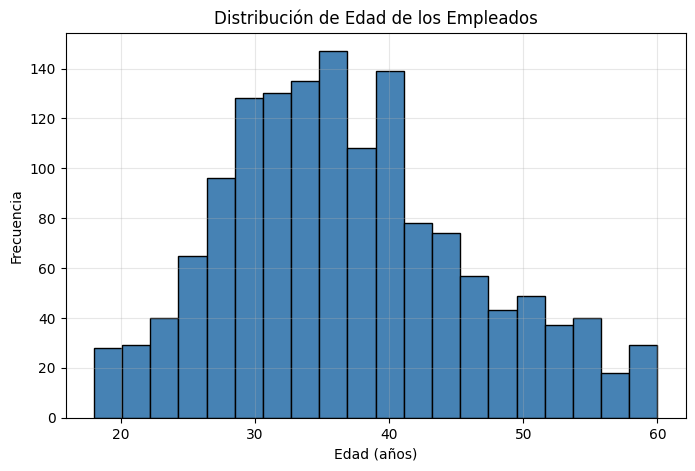

In [10]:
#Edad
plt.figure(figsize=(8, 5))
plt.hist(df_clean['Age'], bins=20, color='steelblue', edgecolor='black')
plt.title('Distribución de Edad de los Empleados')
plt.xlabel('Edad (años)')
plt.ylabel('Frecuencia')
plt.grid(True, alpha=0.3)
plt.show()

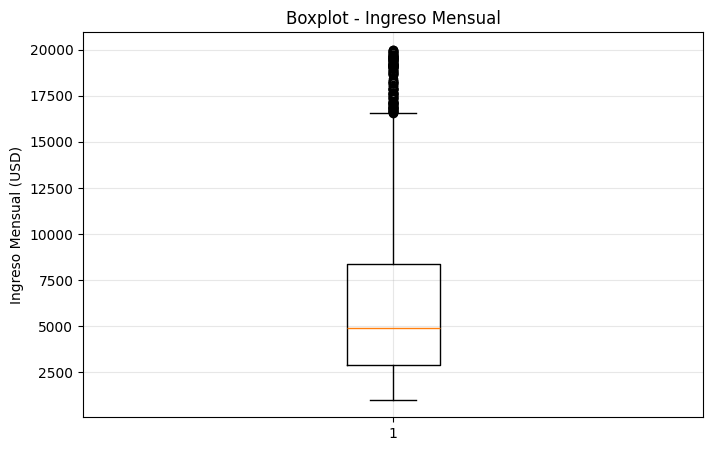

In [11]:
#Ingreso Mensual
plt.figure(figsize=(8, 5))
plt.boxplot(df_clean['MonthlyIncome'])
plt.title('Boxplot - Ingreso Mensual')
plt.ylabel('Ingreso Mensual (USD)')
plt.grid(True, alpha=0.3)
plt.show()

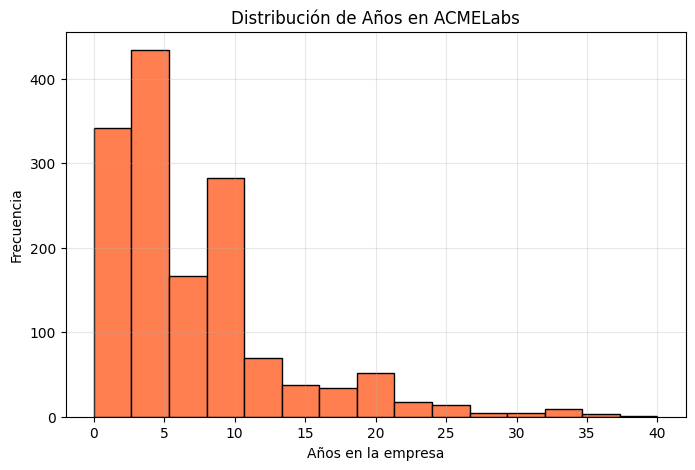

In [12]:
#Años en la Empresa
plt.figure(figsize=(8, 5))
plt.hist(df_clean['YearsAtCompany'], bins=15, color='coral', edgecolor='black')
plt.title('Distribución de Años en ACMELabs')
plt.xlabel('Años en la empresa')
plt.ylabel('Frecuencia')
plt.grid(True, alpha=0.3)
plt.show()

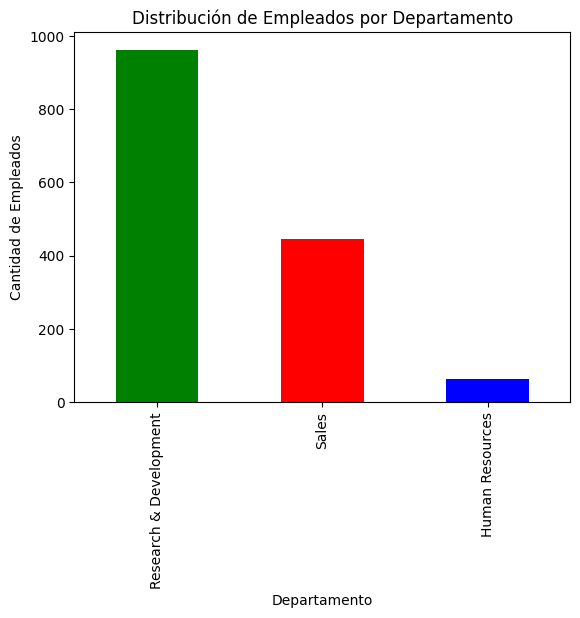

In [13]:
#Departamento
conteo = df_clean['Department'].value_counts()
conteo.plot(kind='bar', color=['green', 'red', 'blue'])
plt.title('Distribución de Empleados por Departamento')
plt.xlabel('Departamento')
plt.ylabel('Cantidad de Empleados')
plt.show()

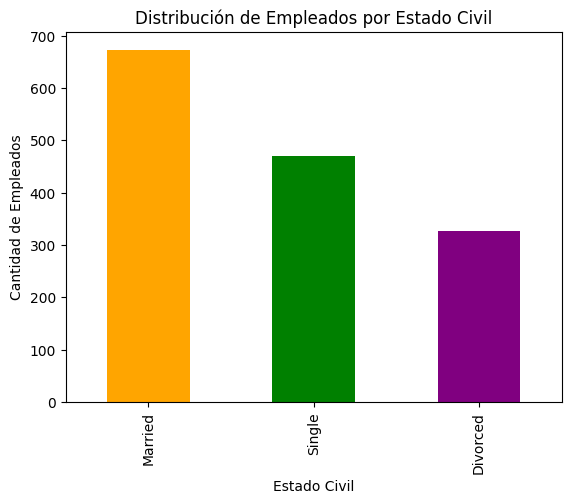

In [14]:
#Estado Civil
conteo = df_clean['MaritalStatus'].value_counts()
conteo.plot(kind='bar', color=['orange', 'green', 'purple'])
plt.title('Distribución de Empleados por Estado Civil')
plt.xlabel('Estado Civil')
plt.ylabel('Cantidad de Empleados')
plt.show()

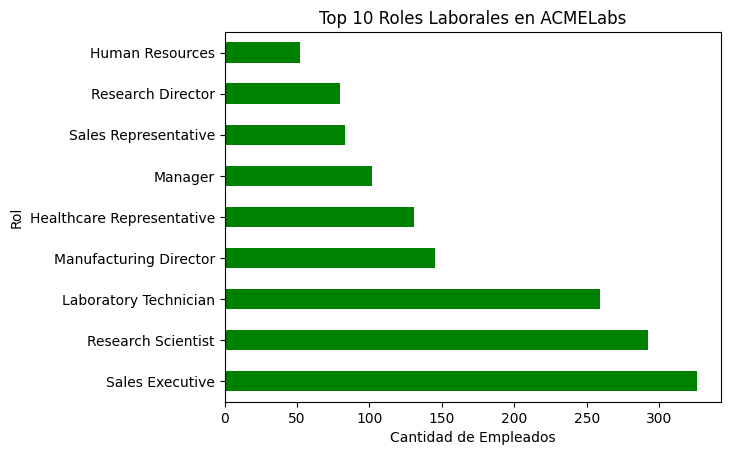

In [15]:
#Top 10 Roles Laborales
top_roles = df_clean['JobRole'].value_counts().head(10)
top_roles.plot(kind='barh', color='green')
plt.title('Top 10 Roles Laborales en ACMELabs')
plt.xlabel('Cantidad de Empleados')
plt.ylabel('Rol')
plt.show()

Análisis de tasa de deserción por cada variable categórica (100% stacked bar charts).

In [16]:
print("="*60)
print("          TASA DE DESERCIÓN POR CATEGORÍA")
print("="*60)

categorias = {
    'Department': 'Departamento',
    'MaritalStatus': 'Estado Civil',
    'OverTime': 'Horas Extras'
}

for columna, nombre in categorias.items():
    print(f"\n{nombre}:")
    print("-" * 40)

    for valor in df_clean[columna].unique():
        total = len(df_clean[df_clean[columna] == valor])
        desertores = len(df_clean[(df_clean[columna] == valor) & (df_clean['Attrition'] == 'Yes')])
        porcentaje = (desertores / total) * 100
        print(f"  {valor:12} | {porcentaje:5.1f}%")

          TASA DE DESERCIÓN POR CATEGORÍA

Departamento:
----------------------------------------
  Sales        |  20.6%
  Research & Development |  13.8%
  Human Resources |  19.0%

Estado Civil:
----------------------------------------
  Single       |  25.5%
  Married      |  12.5%
  Divorced     |  10.1%

Horas Extras:
----------------------------------------
  Yes          |  30.5%
  No           |  10.4%


departamento

In [17]:
deptos = df_clean['Department'].unique()
no = []
si = []

for d in deptos:
    datos = df_clean[df_clean['Department'] == d]
    total = len(datos)
    no.append((len(datos[datos['Attrition'] == 'No']) / total) * 100)
    si.append((len(datos[datos['Attrition'] == 'Yes']) / total) * 100)

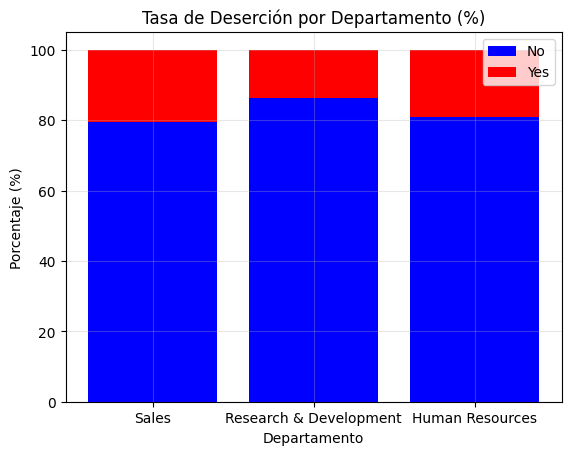

In [18]:
x = np.arange(len(deptos))
plt.bar(x, no, color='blue', label='No')
plt.bar(x, si, bottom=no, color='red', label='Yes')

plt.title('Tasa de Deserción por Departamento (%)')
plt.xlabel('Departamento')
plt.ylabel('Porcentaje (%)')
plt.xticks(x, deptos)
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

estado civil

In [19]:
estados = df_clean['MaritalStatus'].unique()
no = []
si = []

for e in estados:
    datos = df_clean[df_clean['MaritalStatus'] == e]
    total = len(datos)
    no.append((len(datos[datos['Attrition'] == 'No']) / total) * 100)
    si.append((len(datos[datos['Attrition'] == 'Yes']) / total) * 100)


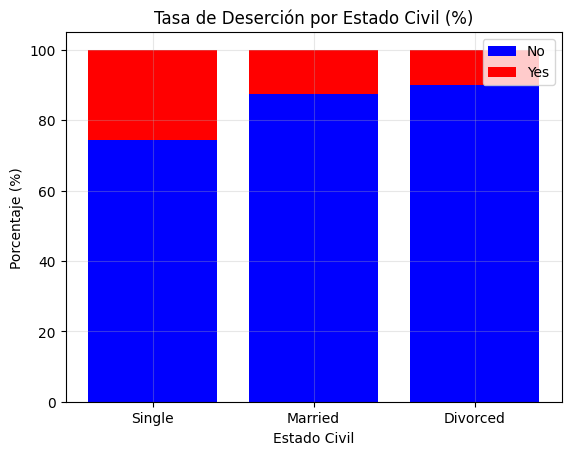

In [20]:
x = np.arange(len(estados))
plt.bar(x, no, color='blue', label='No')
plt.bar(x, si, bottom=no, color='red', label='Yes')

plt.title('Tasa de Deserción por Estado Civil (%)')
plt.xlabel('Estado Civil')
plt.ylabel('Porcentaje (%)')
plt.xticks(x, estados)
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

Crea un gráfico de barras apiladas para cualquier categoría

In [21]:
def graficar_barras_apiladas(df, columna, titulo):
    """Crea un gráfico de barras apiladas para cualquier categoría"""

    categorias = df[columna].unique()
    no_desertores = []
    desertores = []

    for cat in categorias:
        empleados_cat = df[df[columna] == cat]
        total = len(empleados_cat)

        no = len(empleados_cat[empleados_cat['Attrition'] == 'No'])
        si = len(empleados_cat[empleados_cat['Attrition'] == 'Yes'])

        no_desertores.append((no / total) * 100)
        desertores.append((si / total) * 100)

    x = np.arange(len(categorias))

    plt.bar(x, no_desertores, color='blue', label='No')
    plt.bar(x, desertores, bottom=no_desertores, color='red', label='Yes')

    plt.title(titulo)
    plt.xlabel(columna)
    plt.ylabel('Porcentaje (%)')
    plt.xticks(x, categorias)
    plt.legend(title='Attrition')
    plt.grid(True, alpha=0.3)
    plt.show()

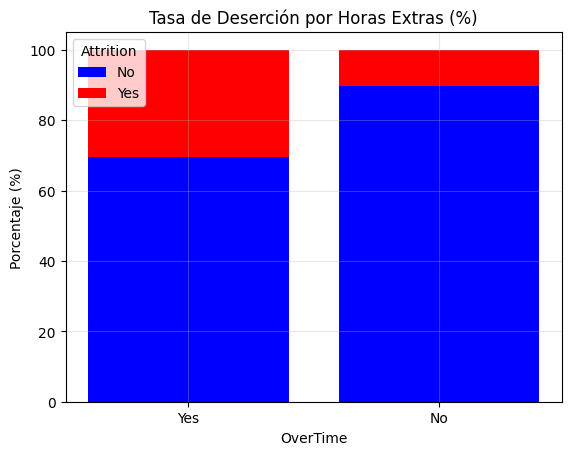

In [22]:
graficar_barras_apiladas(df_clean, 'OverTime', 'Tasa de Deserción por Horas Extras (%)')

Mapa de calor de correlaciones entre variables numéricas.

MAPA DE CORRELACIONES


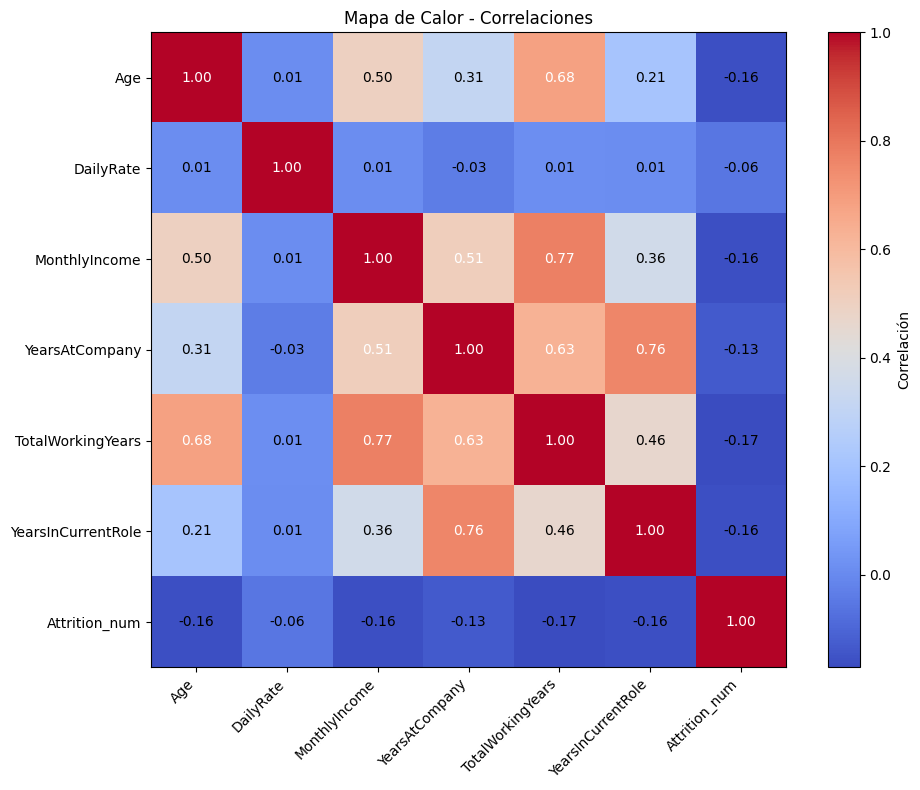


CORRELACIONES CON ATTRITION

Variables ordenadas por correlación:
  TotalWorkingYears: 0.1711
  YearsInCurrentRole: 0.1605
  MonthlyIncome: 0.1598
  Age: 0.1592
  YearsAtCompany: 0.1344
  DailyRate: 0.0567


In [23]:

#mAPA DE CORRELACIONES

print("="*60)
print("MAPA DE CORRELACIONES")
print("="*60)

# Variables numéricas
variables = ['Age', 'DailyRate', 'MonthlyIncome', 'YearsAtCompany',
             'TotalWorkingYears', 'YearsInCurrentRole']

# Copiar datos
df_temp = df_clean.copy()

# Convertir Attrition a número
df_temp['Attrition_num'] = 0
for i in range(len(df_temp)):
    if df_temp['Attrition'].iloc[i] == 'Yes':
        df_temp['Attrition_num'].iloc[i] = 1

variables.append('Attrition_num')

# Crear matriz de correlación
n = len(variables)
matriz_correlacion = np.zeros((n, n))

for i in range(n):
    for j in range(n):
        if i == j:
            matriz_correlacion[i][j] = 1.0
        else:
            x = df_temp[variables[i]].values
            y = df_temp[variables[j]].values

            mean_x = sum(x) / len(x)
            mean_y = sum(y) / len(y)

            numerador = 0
            denom_x = 0
            denom_y = 0

            for k in range(len(x)):
                numerador += (x[k] - mean_x) * (y[k] - mean_y)
                denom_x += (x[k] - mean_x) ** 2
                denom_y += (y[k] - mean_y) ** 2

            if denom_x * denom_y != 0:
                matriz_correlacion[i][j] = numerador / (denom_x ** 0.5 * denom_y ** 0.5)
            else:
                matriz_correlacion[i][j] = 0

# Graficar mapa de calor
plt.figure(figsize=(10, 8))
plt.imshow(matriz_correlacion, cmap='coolwarm', interpolation='nearest')
plt.colorbar(label='Correlación')

plt.xticks(range(n), variables, rotation=45, ha='right')
plt.yticks(range(n), variables)

# Agregar valores
for i in range(n):
    for j in range(n):
        color = 'white' if abs(matriz_correlacion[i][j]) > 0.5 else 'black'
        plt.text(j, i, f'{matriz_correlacion[i][j]:.2f}',
                ha='center', va='center', color=color)

plt.title('Mapa de Calor - Correlaciones')
plt.tight_layout()
plt.show()

# Correlaciones con Attrition
print("\n" + "="*60)
print("CORRELACIONES CON ATTRITION")
print("="*60)

corr_attrition = matriz_correlacion[-1, :-1]

print("\nVariables ordenadas por correlación:")
corr_list = []
for i in range(len(variables[:-1])):
    corr_list.append((variables[i], abs(corr_attrition[i])))

for i in range(len(corr_list)):
    for j in range(i + 1, len(corr_list)):
        if corr_list[i][1] < corr_list[j][1]:
            temp = corr_list[i]
            corr_list[i] = corr_list[j]
            corr_list[j] = temp

for var, corr in corr_list:
    print(f"  {var}: {corr:.4f}")

5.1.3  Preprocesamiento para ML • Encoding de variables categóricas: Label Encoding para ordinales, One-Hot Encoding para nominales. • Eliminación de la columna Attrition del conjunto de features (se usará solo para evaluación posterior). • Escalado con StandardScaler o MinMaxScaler — justificar la elección. • Separar la variable Attrition como vector de evaluación (no para entrenar).

In [24]:
print("="*60)
print("⚙️ PREPROCESAMIENTO PARA MACHINE LEARNING")
print("="*60)

print("\n🔹 PASO 1: Separar Attrition")

attrition = df_clean['Attrition']
attrition_binary = (attrition == 'Yes').astype(int)  # Convertir a 0 y 1

df_features = df_clean.drop(columns=['Attrition'])

print(f"  ✅ Attrition separada: {attrition.shape[0]} registros")
print(f"  ✅ Features sin Attrition: {df_features.shape[1]} variables")
print(f"  📊 Columnas: {df_features.columns.tolist()}")

⚙️ PREPROCESAMIENTO PARA MACHINE LEARNING

🔹 PASO 1: Separar Attrition
  ✅ Attrition separada: 1470 registros
  ✅ Features sin Attrition: 31 variables
  📊 Columnas: ['Age', 'BusinessTravel', 'DailyRate', 'Department', 'DistanceFromHome', 'Education', 'EducationField', 'EmployeeNumber', 'EnvironmentSatisfaction', 'Gender', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobRole', 'JobSatisfaction', 'MaritalStatus', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'OverTime', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']


In [25]:
print("\n🔹 PASO 2: Identificar variables categóricas")
categorical_cols = df_features.select_dtypes(include=['object']).columns.tolist()
print(f"  ✅ Columnas categóricas encontradas: {categorical_cols}")

print("\n  📊 Valores únicos por columna categórica:")
for col in categorical_cols:
    print(f"    - {col}: {df_features[col].nunique()} valores únicos")
    print(f"      Ejemplos: {df_features[col].unique()[:3]}")


🔹 PASO 2: Identificar variables categóricas
  ✅ Columnas categóricas encontradas: ['BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'OverTime']

  📊 Valores únicos por columna categórica:
    - BusinessTravel: 3 valores únicos
      Ejemplos: ['Travel_Rarely' 'Travel_Frequently' 'Non-Travel']
    - Department: 3 valores únicos
      Ejemplos: ['Sales' 'Research & Development' 'Human Resources']
    - EducationField: 6 valores únicos
      Ejemplos: ['Life Sciences' 'Other' 'Medical']
    - Gender: 2 valores únicos
      Ejemplos: ['Female' 'Male']
    - JobRole: 9 valores únicos
      Ejemplos: ['Sales Executive' 'Research Scientist' 'Laboratory Technician']
    - MaritalStatus: 3 valores únicos
      Ejemplos: ['Single' 'Married' 'Divorced']
    - OverTime: 2 valores únicos
      Ejemplos: ['Yes' 'No']


In [26]:
print("\n🔹 PASO 3: One-Hot Encoding")


df_encoded = pd.get_dummies(df_features, columns=categorical_cols, drop_first=False)

print(f"  ✅ One-Hot Encoding completado")
print(f"  📊 Dimensiones antes: {df_features.shape}")
print(f"  📊 Dimensiones después: {df_encoded.shape}")


print("\n  📊 Ejemplo de columnas nuevas (primeras 5):")
nuevas_columnas = [col for col in df_encoded.columns if any(cat in col for cat in categorical_cols)]
print(f"    {nuevas_columnas[:5]}")


🔹 PASO 3: One-Hot Encoding
  ✅ One-Hot Encoding completado
  📊 Dimensiones antes: (1470, 31)
  📊 Dimensiones después: (1470, 52)

  📊 Ejemplo de columnas nuevas (primeras 5):
    ['BusinessTravel_Non-Travel', 'BusinessTravel_Travel_Frequently', 'BusinessTravel_Travel_Rarely', 'Department_Human Resources', 'Department_Research & Development']


¿Por qué StandardSca
Todas las variables quedan con media 0 y desviación estándar 1
Es mejor que MinMaxScaler cuando hay outliers (como en MonthlyIncome)
Es el más usado para PCA y K-Means

In [27]:
print("\n🔹 PASO 4: Escalado con StandardScaler")

from sklearn.preprocessing import StandardScaler


scaler = StandardScaler()

X_scaled = scaler.fit_transform(df_encoded)

X_scaled_df = pd.DataFrame(X_scaled, columns=df_encoded.columns)

print(f"  ✅ Escalado completado")
print(f"  📊 Datos escalados: {X_scaled_df.shape}")

print("\n  📊 Verificación del escalado (primeras 3 columnas):")
for col in X_scaled_df.columns[:3]:
    print(f"    - {col}: media={X_scaled_df[col].mean():.2f}, std={X_scaled_df[col].std():.2f}")

print("\n  📊 Primeras 5 filas escaladas:")
print(X_scaled_df.head())



🔹 PASO 4: Escalado con StandardScaler
  ✅ Escalado completado
  📊 Datos escalados: (1470, 52)

  📊 Verificación del escalado (primeras 3 columnas):
    - Age: media=-0.00, std=1.00
    - DailyRate: media=0.00, std=1.00
    - DistanceFromHome: media=0.00, std=1.00

  📊 Primeras 5 filas escaladas:
        Age  DailyRate  DistanceFromHome  Education  EmployeeNumber  \
0  0.446350   0.742527         -1.010909  -0.891688       -1.701283   
1  1.322365  -1.297775         -0.147150  -1.868426       -1.699621   
2  0.008343   1.414363         -0.887515  -0.891688       -1.696298   
3 -0.429664   1.461466         -0.764121   1.061787       -1.694636   
4 -1.086676  -0.524295         -0.887515  -1.868426       -1.691313   

   EnvironmentSatisfaction  HourlyRate  JobInvolvement  JobLevel  \
0                -0.660531    1.383138        0.379672 -0.057788   
1                 0.254625   -0.240677       -1.026167 -0.057788   
2                 1.169781    1.284725       -1.026167 -0.961486   
3  

In [28]:
print("\n🔹 PASO 5: Guardar archivos")

X_scaled_df.to_csv('X_scaled.csv', index=False)
pd.DataFrame(attrition_binary).to_csv('attrition_binary.csv', index=False)

print("  💾 Archivos guardados:")
print("    - X_scaled.csv (features escalados)")
print("    - attrition_binary.csv (variable objetivo)")



🔹 PASO 5: Guardar archivos
  💾 Archivos guardados:
    - X_scaled.csv (features escalados)
    - attrition_binary.csv (variable objetivo)


In [29]:
print("\n" + "="*60)
print("📊 RESUMEN FINAL DEL PREPROCESAMIENTO")
print("="*60)
print(f"""
  ✅ Attrition separada: {attrition_binary.shape[0]} registros
  ✅ Variables originales: {df_features.shape[1]}
  ✅ Variables después de One-Hot: {df_encoded.shape[1]}
  ✅ Datos escalados: {X_scaled_df.shape}
  ✅ Media de datos escalados: {X_scaled_df.mean().mean():.2f}
  ✅ Desviación de datos escalados: {X_scaled_df.std().mean():.2f}
""")

print("✅ PREPROCESAMIENTO COMPLETADO CON ÉXITO")



📊 RESUMEN FINAL DEL PREPROCESAMIENTO

  ✅ Attrition separada: 1470 registros
  ✅ Variables originales: 31
  ✅ Variables después de One-Hot: 52
  ✅ Datos escalados: (1470, 52)
  ✅ Media de datos escalados: 0.00
  ✅ Desviación de datos escalados: 1.00

✅ PREPROCESAMIENTO COMPLETADO CON ÉXITO


#5.2  Etapa 2 — Reducción de Dimensionalidad
5.2  Etapa 2 — Reducción de Dimensionalidad

In [30]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

ANÁLISIS DE COMPONENTES PRINCIPALES

Datos cargados: 1470 registros, 52 variables

Varianza explicada por los primeros 10 componentes:
  PC1: 10.29%
  PC2: 6.74%
  PC3: 5.08%
  PC4: 4.15%
  PC5: 4.04%
  PC6: 3.85%
  PC7: 3.76%
  PC8: 3.48%
  PC9: 3.42%
  PC10: 3.10%


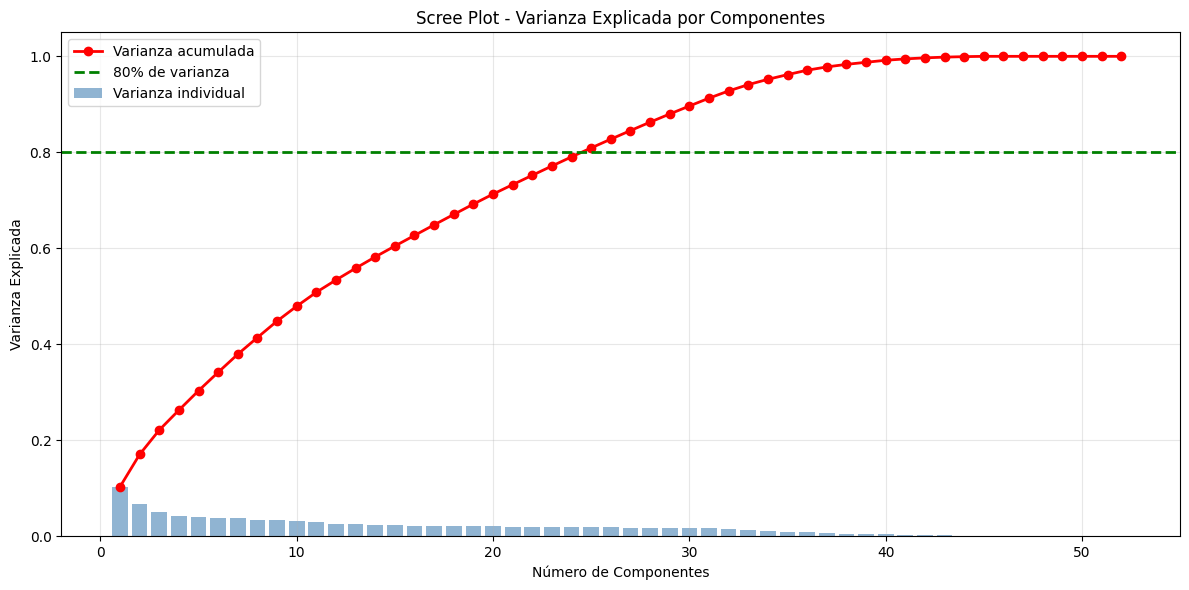


Componentes necesarios para 80% de varianza: 25
Varianza explicada: 80.91%
Datos reducidos: de 52 a 25 dimensiones

Archivo guardado: X_pca_reducido.csv


In [31]:

#analisis de componentes

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

print("="*60)
print("ANÁLISIS DE COMPONENTES PRINCIPALES")
print("="*60)

X_scaled_df = pd.read_csv('X_scaled.csv')
attrition_binary = pd.read_csv('attrition_binary.csv')

print(f"\nDatos cargados: {X_scaled_df.shape[0]} registros, {X_scaled_df.shape[1]} variables")

pca = PCA()
pca.fit(X_scaled_df)

#varianza
varianza_explicada = pca.explained_variance_ratio_
varianza_acumulada = np.cumsum(varianza_explicada)

print("\nVarianza explicada por los primeros 10 componentes:")
for i in range(10):
    print(f"  PC{i+1}: {varianza_explicada[i]:.2%}")

#scree Plot
plt.figure(figsize=(12, 6))
plt.bar(range(1, len(varianza_explicada) + 1), varianza_explicada,
        alpha=0.6, color='steelblue', label='Varianza individual')
plt.plot(range(1, len(varianza_acumulada) + 1), varianza_acumulada,
         'ro-', linewidth=2, label='Varianza acumulada')
plt.axhline(y=0.80, color='green', linestyle='--', linewidth=2, label='80% de varianza')
plt.xlabel('Número de Componentes')
plt.ylabel('Varianza Explicada')
plt.title('Scree Plot - Varianza Explicada por Componentes')
plt.legend(loc='best')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

#80%
n_componentes_80 = 0
for i, var in enumerate(varianza_acumulada):
    if var >= 0.80:
        n_componentes_80 = i + 1
        break

varianza_80 = varianza_acumulada[n_componentes_80 - 1]

print(f"\nComponentes necesarios para 80% de varianza: {n_componentes_80}")
print(f"Varianza explicada: {varianza_80:.2%}")

pca_optimo = PCA(n_components=n_componentes_80, random_state=42)
X_pca_reducido = pca_optimo.fit_transform(X_scaled_df)

print(f"Datos reducidos: de {X_scaled_df.shape[1]} a {X_pca_reducido.shape[1]} dimensiones")

pd.DataFrame(X_pca_reducido).to_csv('X_pca_reducido.csv', index=False)
print("\nArchivo guardado: X_pca_reducido.csv")

PCA - VISUALIZACIÓN 2D

PC1: 10.29%
PC2: 6.74%


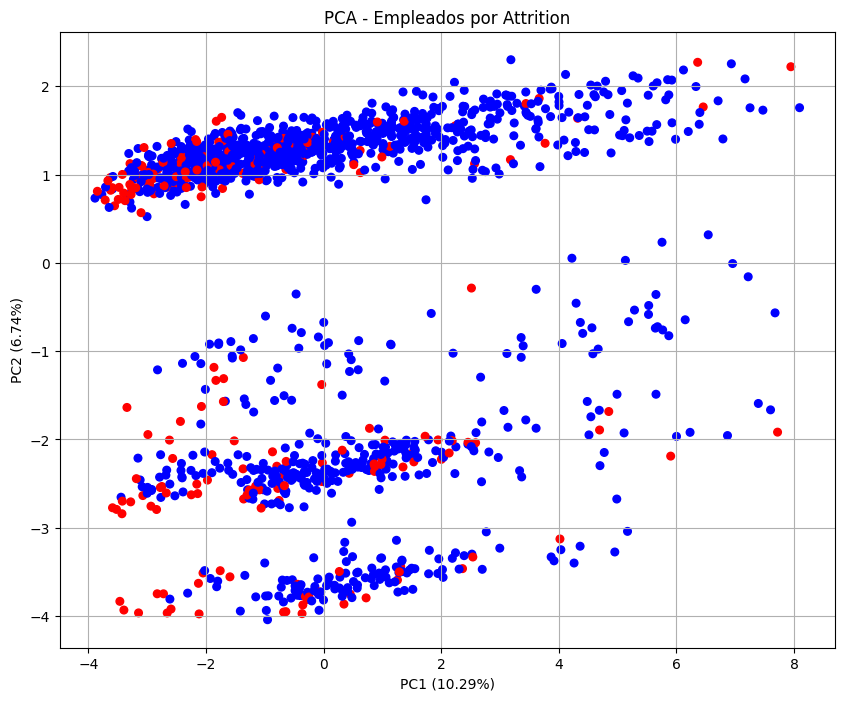


Guardado: X_pca_2d.csv


In [32]:

# PCA - VERSIÓN SIMPLE

from sklearn.decomposition import PCA

print("="*60)
print("PCA - VISUALIZACIÓN 2D")
print("="*60)

X = pd.read_csv('X_scaled.csv').values
attrition = pd.read_csv('attrition_binary.csv').values.flatten()

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X)

print(f"\nPC1: {pca.explained_variance_ratio_[0]:.2%}")
print(f"PC2: {pca.explained_variance_ratio_[1]:.2%}")

colores = []
for val in attrition:
    if val == 0:
        colores.append('blue')
    else:
        colores.append('red')

plt.figure(figsize=(10, 8))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=colores, s=30)
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.2%})')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.2%})')
plt.title('PCA - Empleados por Attrition')
plt.grid(True)
plt.show()

pd.DataFrame(X_pca, columns=['PC1', 'PC2']).to_csv('X_pca_2d.csv', index=False)
print("\nGuardado: X_pca_2d.csv")

ANÁLISIS DE LOADINGS

TOP 5 VARIABLES QUE DEFINEN PC1:
  JobLevel: 0.3805
  MonthlyIncome: 0.3740
  TotalWorkingYears: 0.3740
  YearsAtCompany: 0.3417
  YearsInCurrentRole: 0.2883

TOP 5 VARIABLES QUE DEFINEN PC2:
  Department_Research & Development: 0.5071
  Department_Sales: 0.4974
  JobRole_Sales Executive: 0.4217
  EducationField_Marketing: 0.3429
  JobRole_Sales Representative: 0.1919

INTERPRETACIÓN EN TÉRMINOS DE RRHH

PC1 - DIMENSIÓN DE EXPERIENCIA Y SALARIO:
  • JobLevel
  • MonthlyIncome
  • TotalWorkingYears

PC2 - DIMENSIÓN DE SATISFACCIÓN LABORAL:
  • Department_Research & Development
  • Department_Sales
  • JobRole_Sales Executive

Generando biplot...


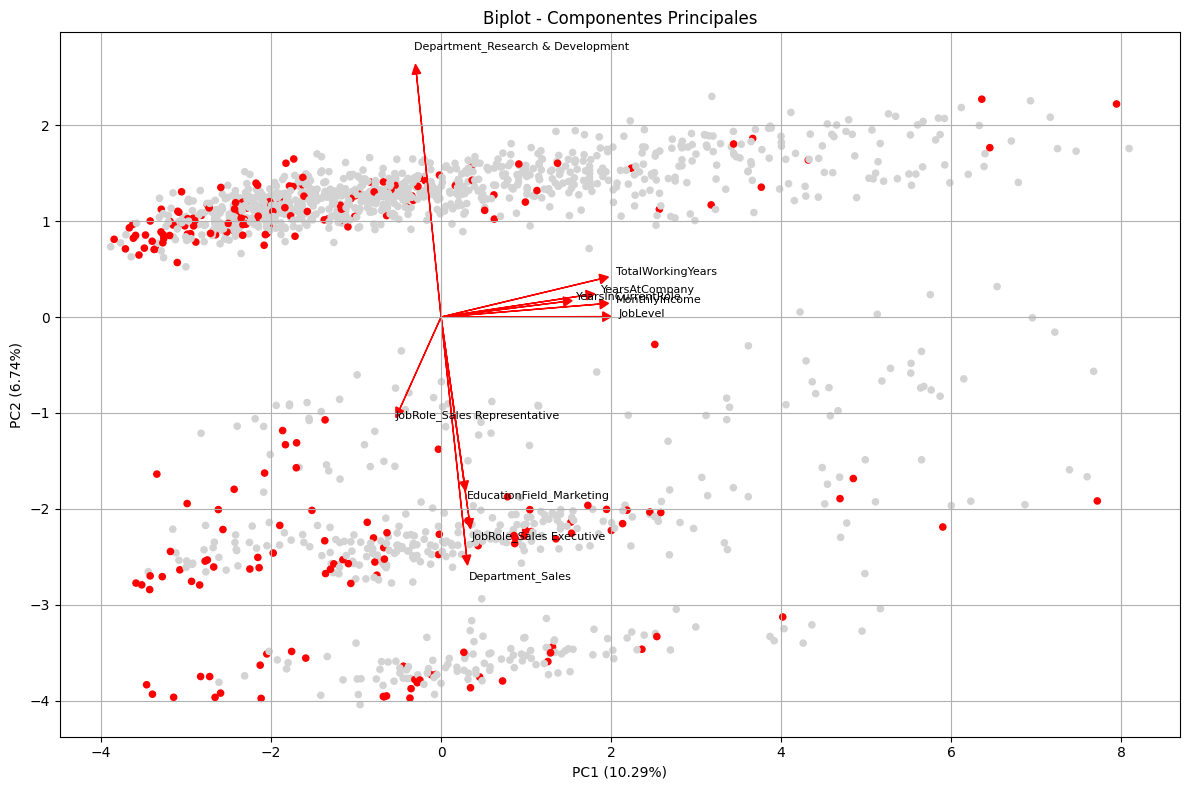


PCA COMPLETADO


In [33]:
# ANÁLISIS DE LOADINGS

from sklearn.decomposition import PCA

print("="*60)
print("ANÁLISIS DE LOADINGS")
print("="*60)

X_scaled_df = pd.read_csv('X_scaled.csv')
X_pca_2 = pd.read_csv('X_pca_2d.csv').values
attrition_binary = pd.read_csv('attrition_binary.csv')

pca_2 = PCA(n_components=2, random_state=42)
pca_2.fit(X_scaled_df)

loadings = pd.DataFrame(
    pca_2.components_.T,
    columns=['PC1', 'PC2'],
    index=X_scaled_df.columns
)

print("\nTOP 5 VARIABLES QUE DEFINEN PC1:")
lista_pc1 = []
for var in loadings.index:
    lista_pc1.append((var, abs(loadings.loc[var, 'PC1'])))

for i in range(len(lista_pc1)):
    for j in range(i + 1, len(lista_pc1)):
        if lista_pc1[i][1] < lista_pc1[j][1]:
            temp = lista_pc1[i]
            lista_pc1[i] = lista_pc1[j]
            lista_pc1[j] = temp

for i in range(5):
    print(f"  {lista_pc1[i][0]}: {lista_pc1[i][1]:.4f}")

print("\nTOP 5 VARIABLES QUE DEFINEN PC2:")
lista_pc2 = []
for var in loadings.index:
    lista_pc2.append((var, abs(loadings.loc[var, 'PC2'])))

for i in range(len(lista_pc2)):
    for j in range(i + 1, len(lista_pc2)):
        if lista_pc2[i][1] < lista_pc2[j][1]:
            temp = lista_pc2[i]
            lista_pc2[i] = lista_pc2[j]
            lista_pc2[j] = temp

for i in range(5):
    print(f"  {lista_pc2[i][0]}: {lista_pc2[i][1]:.4f}")

print("\n" + "="*60)
print("INTERPRETACIÓN EN TÉRMINOS DE RRHH")
print("="*60)

print("\nPC1 - DIMENSIÓN DE EXPERIENCIA Y SALARIO:")
for i in range(3):
    print(f"  • {lista_pc1[i][0]}")

print("\nPC2 - DIMENSIÓN DE SATISFACCIÓN LABORAL:")
for i in range(3):
    print(f"  • {lista_pc2[i][0]}")

#biplot
print("\nGenerando biplot...")

vars_biplot = []
for i in range(5):
    vars_biplot.append(lista_pc1[i][0])
for i in range(5):
    if lista_pc2[i][0] not in vars_biplot:
        vars_biplot.append(lista_pc2[i][0])

colores = []
for val in attrition_binary.values.flatten():
    if val == 0:
        colores.append('lightgray')
    else:
        colores.append('red')

plt.figure(figsize=(12, 8))


plt.scatter(X_pca_2[:, 0], X_pca_2[:, 1], c=colores, s=20)

for var in vars_biplot:
    x = loadings.loc[var, 'PC1'] * 5
    y = loadings.loc[var, 'PC2'] * 5

    plt.arrow(0, 0, x, y, head_width=0.1, head_length=0.1,
              color='red', linewidth=1)
    plt.text(x * 1.1, y * 1.1, var, fontsize=8)

plt.xlabel(f'PC1 ({pca_2.explained_variance_ratio_[0]:.2%})')
plt.ylabel(f'PC2 ({pca_2.explained_variance_ratio_[1]:.2%})')
plt.title('Biplot - Componentes Principales')
plt.grid(True)
plt.tight_layout()
plt.show()

print("\n" + "="*60)
print("PCA COMPLETADO")
print("="*60)

#5.2.2  t-SNE o UMAP (Opcional, +5 pts bono)
• Aplicar t-SNE con perplexity entre 30–50 o UMAP con n_neighbors entre 15–30. • Comparar visualmente con PCA: ¿qué técnica muestra mejor separación de grupos? • Colorear los scatter plots con la variable Attrition.

In [34]:

# t-SNE - REDUCCIÓN DE DIMENSIONALIDAD NO LINEAL

from sklearn.manifold import TSNE

print("="*60)
print("APLICANDO t-SNE PARA VISUALIZACIÓN")
print("="*60)


X_scaled_df = pd.read_csv('X_scaled.csv')
attrition_binary = pd.read_csv('attrition_binary.csv')

print(f"\nDatos cargados: {X_scaled_df.shape[0]} registros, {X_scaled_df.shape[1]} variables")


print("\nAplicando t-SNE...")

# t-SNE con perplexity = 30
# random_state=42
tsne = TSNE(n_components=2, perplexity=30, random_state=42)

X_tsne = tsne.fit_transform(X_scaled_df)

print(f"\n✅ t-SNE completado")
print(f"   Datos reducidos de {X_scaled_df.shape[1]} a {X_tsne.shape[1]} dimensiones")

# Guardar resultados
pd.DataFrame(X_tsne, columns=['t-SNE 1', 't-SNE 2']).to_csv('X_tsne.csv', index=False)
print("\n💾 Archivo guardado: X_tsne.csv")

APLICANDO t-SNE PARA VISUALIZACIÓN

Datos cargados: 1470 registros, 52 variables

Aplicando t-SNE...

✅ t-SNE completado
   Datos reducidos de 52 a 2 dimensiones

💾 Archivo guardado: X_tsne.csv



GRÁFICO DE t-SNE POR ATTRITION



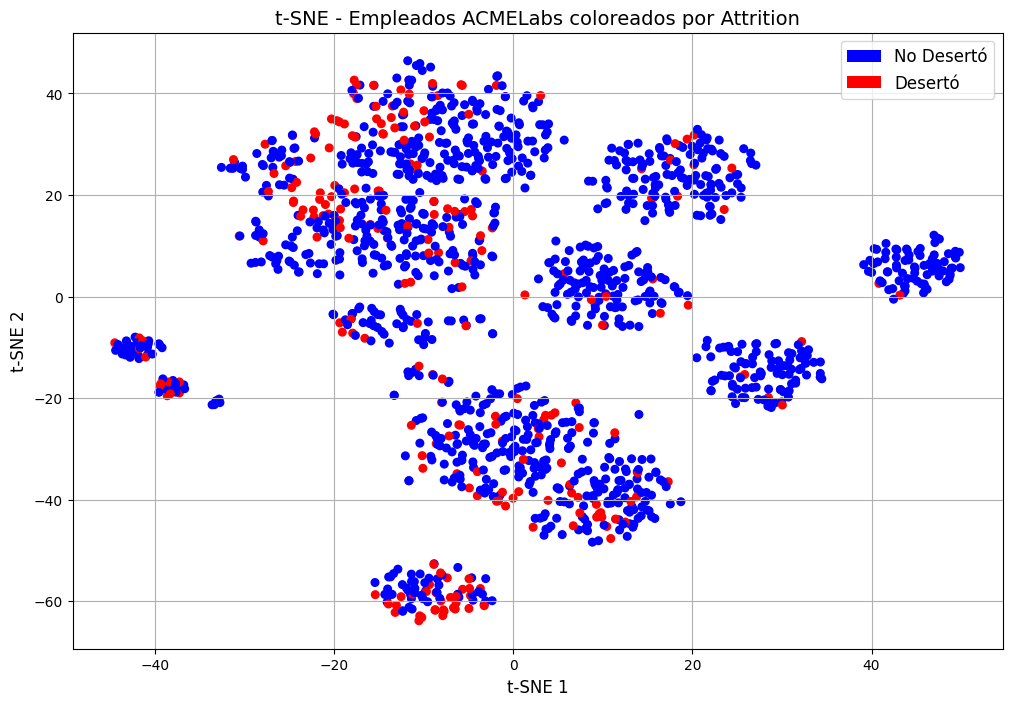


INTERPRETACIÓN DEL GRÁFICO

Total de puntos:
  • Azules (No desertaron): 1233
  • Rojos (Desertaron): 237

Distancia entre grupos:
  • Centro azul: (2.04, -0.68)
  • Centro rojo: (-7.51, -5.85)
  • Distancia: 10.86

✅ Los grupos están SEPARADOS
   → La deserción se puede explicar con los datos
   → Bueno para Machine Learning



In [35]:


print()
print("="*60)
print("GRÁFICO DE t-SNE POR ATTRITION")
print("="*60)
print()


X_tsne = pd.read_csv('X_tsne.csv').values
attrition_binary = pd.read_csv('attrition_binary.csv')

colores = []
for val in attrition_binary.values.flatten():
    if val == 0:
        colores.append('blue')
    else:
        colores.append('red')


plt.figure(figsize=(12, 8))


plt.scatter(X_tsne[:, 0], X_tsne[:, 1], c=colores, s=30)

plt.title('t-SNE - Empleados ACMELabs coloreados por Attrition', fontsize=14)
plt.xlabel('t-SNE 1', fontsize=12)
plt.ylabel('t-SNE 2', fontsize=12)


from matplotlib.patches import Patch
leyenda = [Patch(facecolor='blue', label='No Desertó'),
           Patch(facecolor='red', label='Desertó')]
plt.legend(handles=leyenda, fontsize=12)

plt.grid(True)


plt.show()


print()
print("="*60)
print("INTERPRETACIÓN DEL GRÁFICO")
print("="*60)
print()


puntos_azules = []
puntos_rojos = []

for i in range(len(X_tsne)):
    if colores[i] == 'blue':
        puntos_azules.append(X_tsne[i])
    else:
        puntos_rojos.append(X_tsne[i])

print(f"Total de puntos:")
print(f"  • Azules (No desertaron): {len(puntos_azules)}")
print(f"  • Rojos (Desertaron): {len(puntos_rojos)}")
print()

centro_azul_x = 0
centro_azul_y = 0
for punto in puntos_azules:
    centro_azul_x += punto[0]
    centro_azul_y += punto[1]
if len(puntos_azules) > 0:
    centro_azul_x = centro_azul_x / len(puntos_azules)
    centro_azul_y = centro_azul_y / len(puntos_azules)

centro_rojo_x = 0
centro_rojo_y = 0
for punto in puntos_rojos:
    centro_rojo_x += punto[0]
    centro_rojo_y += punto[1]
if len(puntos_rojos) > 0:
    centro_rojo_x = centro_rojo_x / len(puntos_rojos)
    centro_rojo_y = centro_rojo_y / len(puntos_rojos)


distancia = ((centro_azul_x - centro_rojo_x) ** 2 +
             (centro_azul_y - centro_rojo_y) ** 2) ** 0.5

print(f"Distancia entre grupos:")
print(f"  • Centro azul: ({centro_azul_x:.2f}, {centro_azul_y:.2f})")
print(f"  • Centro rojo: ({centro_rojo_x:.2f}, {centro_rojo_y:.2f})")
print(f"  • Distancia: {distancia:.2f}")
print()

if distancia > 1:
    print("✅ Los grupos están SEPARADOS")
    print("   → La deserción se puede explicar con los datos")
    print("   → Bueno para Machine Learning")
else:
    print("⚠️ Los grupos están MEZCLADOS")
    print("   → La deserción NO se puede explicar fácilmente")
    print("   → Difícil para Machine Learning")

print()
print("="*60)


COMPARACIÓN: PCA vs t-SNE

Vamos a comparar dos técnicas para visualizar datos
  • PCA: Busca preservar la varianza (lineal)
  • t-SNE: Busca preservar los vecinos (no lineal)

PASO 1: Cargar datos
----------------------------------------
  • Datos PCA cargados: (1470, 2)
  • Datos t-SNE cargados: (1470, 2)

PASO 2: Preparar colores
----------------------------------------
  • Azul = No desertó
  • Rojo = Desertó

  • Total de puntos: 1470

PASO 3: Crear gráficos comparativos
----------------------------------------
  • Gráfico 1: PCA (lineal)
  • Gráfico 2: t-SNE (no lineal)



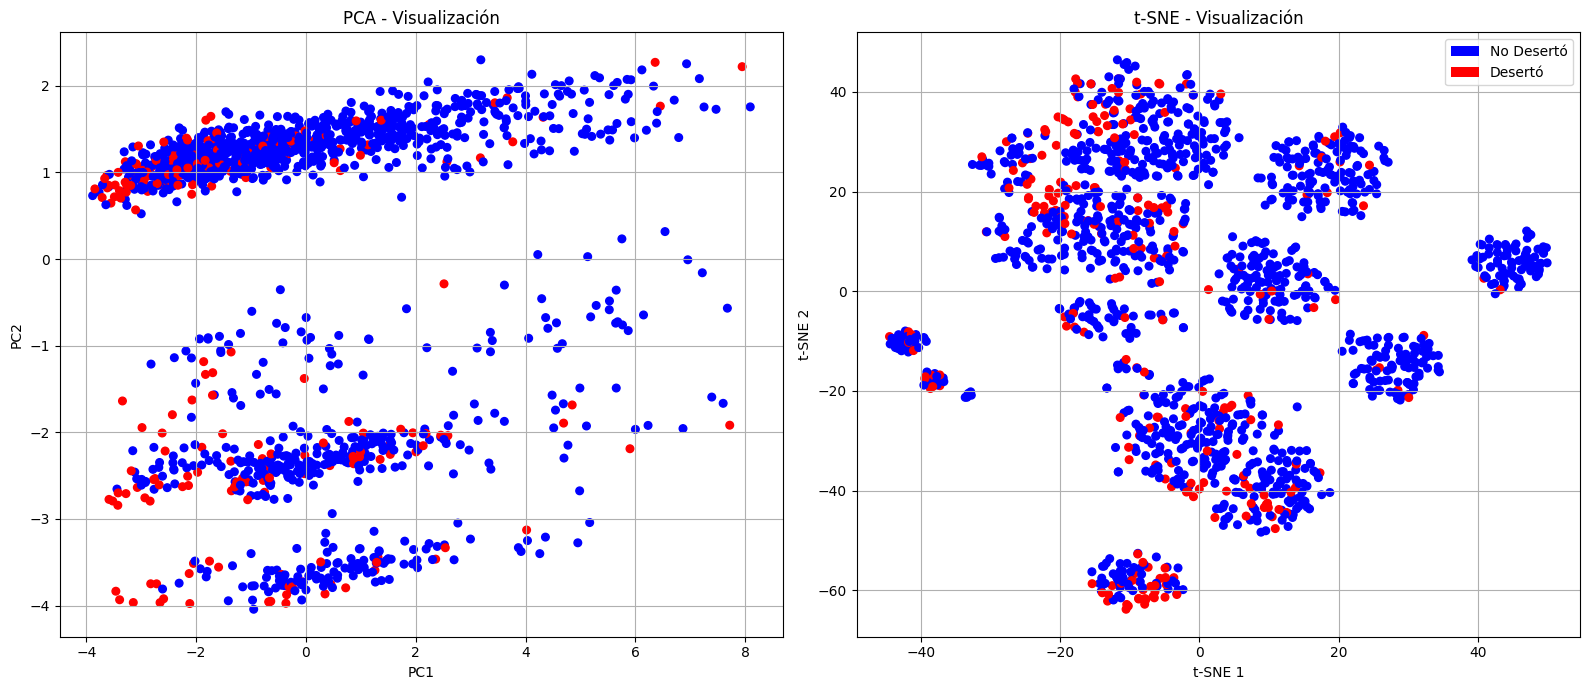


PASO 4: Interpretación de los gráficos
----------------------------------------

¿Qué podemos observar?

🔹 PCA (Gráfico 1):
  • PCA es LINEAL - busca ejes que expliquen la varianza
  • Si los puntos rojos y azules se separan bien:
    → La deserción se explica con combinaciones lineales
  • Si los puntos están mezclados:
    → Los datos no son linealmente separables

🔹 t-SNE (Gráfico 2):
  • t-SNE es NO LINEAL - busca grupos naturales
  • Si los puntos rojos y azules están separados:
    → Hay grupos naturales de desertores
  • Si los puntos están mezclados:
    → No hay grupos claros

🔹 Comparación:
  • PCA es más rápido y determinista
  • t-SNE es más flexible pero más lento
  • PCA preserva distancias globales
  • t-SNE preserva vecinos locales

COMPARACIÓN COMPLETADA


In [36]:

# COMPARACIÓN: PCA vs t-SNE

print()
print("="*60)
print("COMPARACIÓN: PCA vs t-SNE")
print("="*60)
print()
print("Vamos a comparar dos técnicas para visualizar datos")
print("  • PCA: Busca preservar la varianza (lineal)")
print("  • t-SNE: Busca preservar los vecinos (no lineal)")
print()


print("PASO 1: Cargar datos")
print("-" * 40)

X_pca_2 = pd.read_csv('X_pca_2d.csv').values
X_tsne = pd.read_csv('X_tsne.csv').values
attrition_binary = pd.read_csv('attrition_binary.csv')

print(f"  • Datos PCA cargados: {X_pca_2.shape}")
print(f"  • Datos t-SNE cargados: {X_tsne.shape}")
print()


print("PASO 2: Preparar colores")
print("-" * 40)
print("  • Azul = No desertó")
print("  • Rojo = Desertó")
print()


colores_puntos = []
for val in attrition_binary.values.flatten():
    if val == 0:
        colores_puntos.append('blue')
    else:
        colores_puntos.append('red')

print(f"  • Total de puntos: {len(colores_puntos)}")
print()


print("PASO 3: Crear gráficos comparativos")
print("-" * 40)
print("  • Gráfico 1: PCA (lineal)")
print("  • Gráfico 2: t-SNE (no lineal)")
print()

#Crear figura
plt.figure(figsize=(16, 7))


plt.subplot(1, 2, 1)  # 1 fila, 2 columnas, posición 1

plt.scatter(X_pca_2[:, 0], X_pca_2[:, 1], c=colores_puntos, s=30)

plt.title('PCA - Visualización', fontsize=12)
plt.xlabel('PC1')
plt.ylabel('PC2')

plt.grid(True)


#GRAFICO 2: t-SNE


plt.subplot(1, 2, 2)  # 1 fila, 2 columnas, posición 2


plt.scatter(X_tsne[:, 0], X_tsne[:, 1], c=colores_puntos, s=30)


plt.title('t-SNE - Visualización', fontsize=12)
plt.xlabel('t-SNE 1')
plt.ylabel('t-SNE 2')

plt.grid(True)


from matplotlib.patches import Patch

leyenda = [Patch(facecolor='blue', label='No Desertó'),
           Patch(facecolor='red', label='Desertó')]


plt.legend(handles=leyenda, loc='upper right')

plt.tight_layout()
plt.show()
print()


print("PASO 4: Interpretación de los gráficos")
print("-" * 40)
print()

print("¿Qué podemos observar?")
print()

print("🔹 PCA (Gráfico 1):")
print("  • PCA es LINEAL - busca ejes que expliquen la varianza")
print("  • Si los puntos rojos y azules se separan bien:")
print("    → La deserción se explica con combinaciones lineales")
print("  • Si los puntos están mezclados:")
print("    → Los datos no son linealmente separables")
print()

print("🔹 t-SNE (Gráfico 2):")
print("  • t-SNE es NO LINEAL - busca grupos naturales")
print("  • Si los puntos rojos y azules están separados:")
print("    → Hay grupos naturales de desertores")
print("  • Si los puntos están mezclados:")
print("    → No hay grupos claros")
print()

print("🔹 Comparación:")
print("  • PCA es más rápido y determinista")
print("  • t-SNE es más flexible pero más lento")
print("  • PCA preserva distancias globales")
print("  • t-SNE preserva vecinos locales")
print()

print("="*60)
print("COMPARACIÓN COMPLETADA")
print("="*60)

#5.3  Etapa 3 — Clustering
5.3.1  K-Means (Obligatorio) 12. Método del Codo (Elbow): graficar Inertia para k = 2 hasta 10. 13. Silhouette Score: calcular para k = 2 hasta 10 y graficar. 14. Seleccionar el k óptimo justificando con ambas métricas. 15. Ajustar K-Means con el k óptimo y asignar clústeres a cada empleado. 16. Calcular Davies-Bouldin Index para el modelo final.

K-MEANS - MÉTODO DEL CODO Y SILHOUETTE


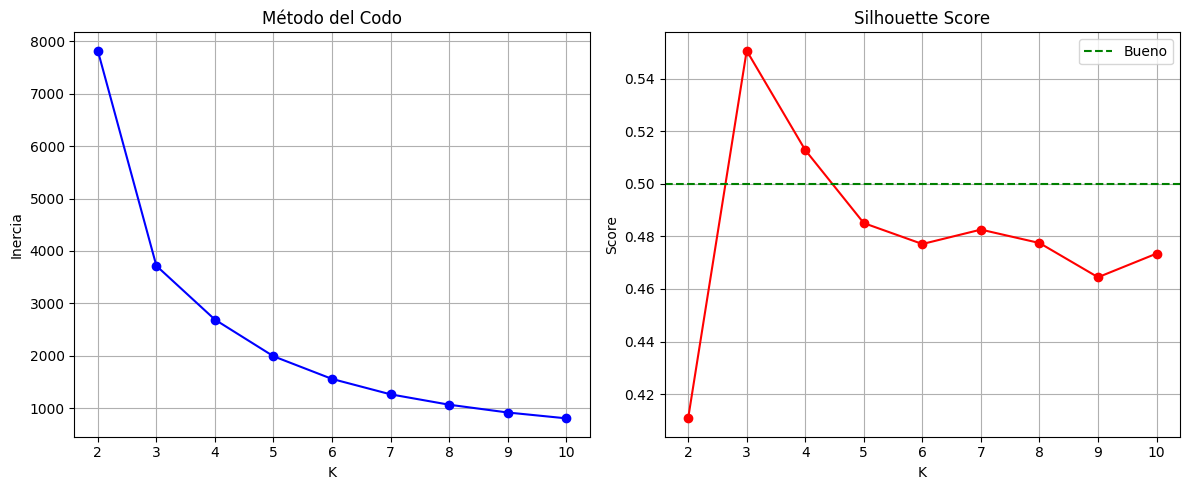


Mejor K: 3
✅ Análisis completado


In [37]:

# K-MEANS

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

print("="*60)
print("K-MEANS - MÉTODO DEL CODO Y SILHOUETTE")
print("="*60)


X = pd.read_csv('X_pca_2d.csv').values


k_vals = []
inercias = []
siluetas = []

for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X)

    k_vals.append(k)
    inercias.append(kmeans.inertia_)
    siluetas.append(silhouette_score(X, kmeans.labels_))

#mejor K
mejor_k = k_vals[0]
for i in range(len(k_vals)):
    if siluetas[i] > siluetas[k_vals.index(mejor_k)]:
        mejor_k = k_vals[i]


plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(k_vals, inercias, color='blue', marker='o', linestyle='-')
plt.title('Método del Codo')
plt.xlabel('K')
plt.ylabel('Inercia')
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(k_vals, siluetas, color='red', marker='o', linestyle='-')
plt.axhline(y=0.5, color='green', linestyle='--', label='Bueno')
plt.title('Silhouette Score')
plt.xlabel('K')
plt.ylabel('Score')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

print(f"\nMejor K: {mejor_k}")
print("✅ Análisis completado")

In [38]:
#SELECCIÓN DEL K ÓPTIMO

print("\n" + "="*60)
print("SELECCIÓN DEL K ÓPTIMO")
print("="*60)


X_pca_2d = pd.read_csv('X_pca_2d.csv').values


k_range = range(2, 11)
inertias = []
silhouette_scores = []

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_pca_2d)
    inertias.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(X_pca_2d, kmeans.labels_))

print("\nResultados:")
print("   K | Inercia | Silhouette")
print("   " + "-"*35)

for i, k in enumerate(k_range):
    print(f"   {k:2d} | {inertias[i]:.0f} | {silhouette_scores[i]:.4f}")


mejor_k_silhouette = k_range[0]
mejor_score = silhouette_scores[0]

for i in range(len(k_range)):
    if silhouette_scores[i] > mejor_score:
        mejor_score = silhouette_scores[i]
        mejor_k_silhouette = k_range[i]

diferencias = []
for i in range(len(inertias) - 1):
    diferencia = inertias[i] - inertias[i + 1]
    diferencias.append(diferencia)

k_elbow = k_range[0]
max_diferencia = diferencias[0]

for i in range(len(diferencias)):
    if diferencias[i] > max_diferencia:
        max_diferencia = diferencias[i]
        k_elbow = k_range[i]

print(f"\nMejor K por Silhouette: {mejor_k_silhouette} (score: {mejor_score:.4f})")
print(f"Punto del codo: {k_elbow}")

#K óptimo
k_optimo = mejor_k_silhouette

print(f"\nK óptimo seleccionado: {k_optimo}")

#ajuste
print(f"\nAjustando K-Means con K={k_optimo}...")

kmeans_final = KMeans(n_clusters=k_optimo, random_state=42, n_init=10)
kmeans_final.fit(X_pca_2d)

clusters = kmeans_final.labels_


df_clusters = pd.DataFrame({
    'PC1': X_pca_2d[:, 0],
    'PC2': X_pca_2d[:, 1],
    'Cluster': clusters
})

df_clusters.to_csv('clusters_kmeans.csv', index=False)
print("\nArchivo guardado: clusters_kmeans.csv")

#Distribución de clústeres
print("\nDistribución de empleados por clúster:")
conteo = df_clusters['Cluster'].value_counts().sort_index()

for cluster in conteo.index:
    print(f"  Cluster {cluster}: {conteo[cluster]} empleados")

print("\n" + "="*60)
print("MODELO K-MEANS COMPLETADO")
print("="*60)


SELECCIÓN DEL K ÓPTIMO

Resultados:
   K | Inercia | Silhouette
   -----------------------------------
    2 | 7821 | 0.4108
    3 | 3716 | 0.5506
    4 | 2689 | 0.5128
    5 | 1989 | 0.4850
    6 | 1557 | 0.4771
    7 | 1263 | 0.4826
    8 | 1065 | 0.4775
    9 | 916 | 0.4644
   10 | 805 | 0.4734

Mejor K por Silhouette: 3 (score: 0.5506)
Punto del codo: 2

K óptimo seleccionado: 3

Ajustando K-Means con K=3...

Archivo guardado: clusters_kmeans.csv

Distribución de empleados por clúster:
  Cluster 0: 732 empleados
  Cluster 1: 434 empleados
  Cluster 2: 304 empleados

MODELO K-MEANS COMPLETADO


EVALUACIÓN DEL MODELO FINAL

Métricas:
  Clústeres: 3
  Inercia: 3716
  Silhouette: 0.5506
  Davies-Bouldin: 0.6516

Interpretación:
  Silhouette: Bueno
  Davies-Bouldin: Bueno


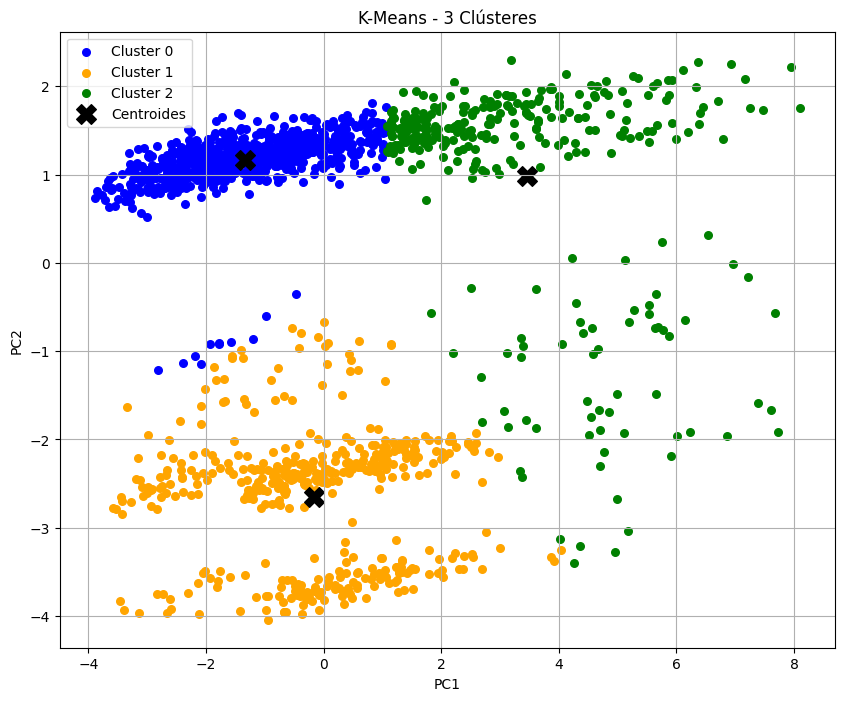


Archivo guardado: resumen_kmeans.csv
✅ Evaluación completada


In [39]:
# EVALUACIÓN DEL MODELO FINAL

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.metrics import davies_bouldin_score

print("="*60)
print("EVALUACIÓN DEL MODELO FINAL")
print("="*60)

X = pd.read_csv('X_pca_2d.csv').values
df_clusters = pd.read_csv('clusters_kmeans.csv')
clusters = df_clusters['Cluster'].values

#re-entrenar
kmeans = KMeans(n_clusters=len(np.unique(clusters)), random_state=42, n_init=10)
kmeans.fit(X)

#metricas
inercia = kmeans.inertia_
silhouette = silhouette_score(X, clusters)
davies = davies_bouldin_score(X, clusters)
n_clusters = len(np.unique(clusters))

print(f"\nMétricas:")
print(f"  Clústeres: {n_clusters}")
print(f"  Inercia: {inercia:.0f}")
print(f"  Silhouette: {silhouette:.4f}")
print(f"  Davies-Bouldin: {davies:.4f}")

print(f"\nInterpretación:")

if silhouette > 0.5:
    print("  Silhouette: Bueno")
elif silhouette > 0.3:
    print("  Silhouette: Aceptable")
else:
    print("  Silhouette: Bajo")

if davies < 1:
    print("  Davies-Bouldin: Bueno")
else:
    print("  Davies-Bouldin: Moderado")

plt.figure(figsize=(10, 8))

colores = ['blue', 'orange', 'green', 'red', 'purple', 'brown', 'pink', 'gray', 'yellow', 'cyan']

for i in range(n_clusters):
    mask = clusters == i
    plt.scatter(X[mask, 0], X[mask, 1],
               c=colores[i % len(colores)], label=f'Cluster {i}', s=30)

plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1],
           c='black', marker='X', s=200, label='Centroides')

plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title(f'K-Means - {n_clusters} Clústeres')
plt.legend()
plt.grid(True)
plt.show()

resumen = pd.DataFrame({
    'Métrica': ['K', 'Inercia', 'Silhouette', 'Davies-Bouldin'],
    'Valor': [n_clusters, f'{inercia:.0f}', f'{silhouette:.4f}', f'{davies:.4f}']
})
resumen.to_csv('resumen_kmeans.csv', index=False)

print("\nArchivo guardado: resumen_kmeans.csv")
print("✅ Evaluación completada")

#5.3.2  Segundo Algoritmo (Elegir uno)
• DBSCAN: Experimentar con eps (0.3–1.5) y min_samples (5–20). Reportar número de clústeres y outliers detectados. • Clustering Jerárquico: Generar dendrograma completo, seleccionar número de clústeres con el criterio de máxima distancia entre fusiones.

In [40]:
# DBSCAN - MEJORES PARÁMETROS
from sklearn.cluster import DBSCAN

print("="*60)
print("DBSCAN - MEJORES PARÁMETROS")
print("="*60)

X = pd.read_csv('X_pca_2d.csv').values

resultados = []

for eps in [0.3, 0.5, 0.7, 1.0, 1.3, 1.5]:
    for min_samples in [5, 10, 15, 20]:
        dbscan = DBSCAN(eps=eps, min_samples=min_samples)
        clusters = dbscan.fit_predict(X)

        #clústeres
        unicos = []
        for c in clusters:
            if c not in unicos:
                unicos.append(c)

        n_clusters = len(unicos)
        if -1 in unicos:
            n_clusters = n_clusters - 1

        #outliers
        outliers = 0
        for c in clusters:
            if c == -1:
                outliers = outliers + 1

        resultados.append({
            'eps': eps,
            'min_samples': min_samples,
            'clusters': n_clusters,
            'outliers': outliers,
            'pct_outliers': (outliers / len(X)) * 100
        })

#combinaciones
validos = []
for r in resultados:
    if r['clusters'] >= 2 and r['pct_outliers'] < 30:
        validos.append(r)

#mejor combinación
if len(validos) > 0:
    mejor = validos[0]
    for r in validos:
        if r['pct_outliers'] < mejor['pct_outliers']:
            mejor = r

    print("\nMEJOR COMBINACIÓN:")
    print(f"  eps = {mejor['eps']}")
    print(f"  min_samples = {mejor['min_samples']}")
    print(f"  Clústeres: {mejor['clusters']}")
    print(f"  Outliers: {mejor['outliers']} ({mejor['pct_outliers']:.1f}%)")
else:
    print("\nNo se encontró combinación válida")

pd.DataFrame(resultados).to_csv('resultados_dbscan.csv', index=False)
print("\nArchivo guardado: resultados_dbscan.csv")

DBSCAN - MEJORES PARÁMETROS

MEJOR COMBINACIÓN:
  eps = 1.0
  min_samples = 5
  Clústeres: 2
  Outliers: 3 (0.2%)

Archivo guardado: resultados_dbscan.csv


In [41]:
# DBSCAN

from sklearn.cluster import DBSCAN

print("="*60)
print("DBSCAN - MODELO FINAL")
print("="*60)

X_pca_2d = pd.read_csv('X_pca_2d.csv').values
attrition_binary = pd.read_csv('attrition_binary.csv')

df_resultados = pd.read_csv('resultados_dbscan.csv')

#2 clusters y menos de 30% outliers
df_validos = df_resultados[(df_resultados['clusters'] >= 2) &
                           (df_resultados['pct_outliers'] < 30)]

if len(df_validos) > 0:
    mejor = df_validos.loc[df_validos['pct_outliers'].idxmin()]
    eps_optimo = mejor['eps']
    min_samples_optimo = int(mejor['min_samples'])
    n_clusters = mejor['clusters']
    n_outliers = mejor['outliers']
    pct_outliers = mejor['pct_outliers']
else:
    eps_optimo = 0.5
    min_samples_optimo = 10
    n_clusters = 0
    n_outliers = 0
    pct_outliers = 0

print(f"\nMejor combinación encontrada:")
print(f"  eps = {eps_optimo}")
print(f"  min_samples = {min_samples_optimo}")
print(f"  Clústeres: {n_clusters}")
print(f"  Outliers: {n_outliers} ({pct_outliers:.1f}%)")

#DBSCAN
dbscan_final = DBSCAN(eps=eps_optimo, min_samples=min_samples_optimo)  # <--- AHORA SÍ FUNCIONA
clusters_dbscan = dbscan_final.fit_predict(X_pca_2d)

#DataFrame
df_clusters = pd.DataFrame({
    'PC1': X_pca_2d[:, 0],
    'PC2': X_pca_2d[:, 1],
    'Cluster_DBSCAN': clusters_dbscan
})

df_clusters.to_csv('clusters_dbscan.csv', index=False)
print("\nArchivo guardado: clusters_dbscan.csv")

resumen = pd.DataFrame({
    'Metrica': ['eps', 'min_samples', 'N_Clusters', 'Outliers', 'Pct_Outliers'],
    'Valor': [eps_optimo, min_samples_optimo, n_clusters, n_outliers, f'{pct_outliers:.1f}%']
})
resumen.to_csv('resumen_dbscan.csv', index=False)
print("Archivo guardado: resumen_dbscan.csv")

print("\n" + "="*60)
print("DBSCAN - MODELO FINAL COMPLETADO")
print("="*60)

DBSCAN - MODELO FINAL

Mejor combinación encontrada:
  eps = 1.0
  min_samples = 5
  Clústeres: 2.0
  Outliers: 3.0 (0.2%)

Archivo guardado: clusters_dbscan.csv
Archivo guardado: resumen_dbscan.csv

DBSCAN - MODELO FINAL COMPLETADO


DBSCAN - VISUALIZACIÓN Y ANÁLISIS

RESULTADOS DBSCAN:
  Clústeres: 2
  Outliers: 3 (0.2%)

Distribución por clúster:
  Outliers: 3
  Cluster 0: 506
  Cluster 1: 961

Generando gráficos...


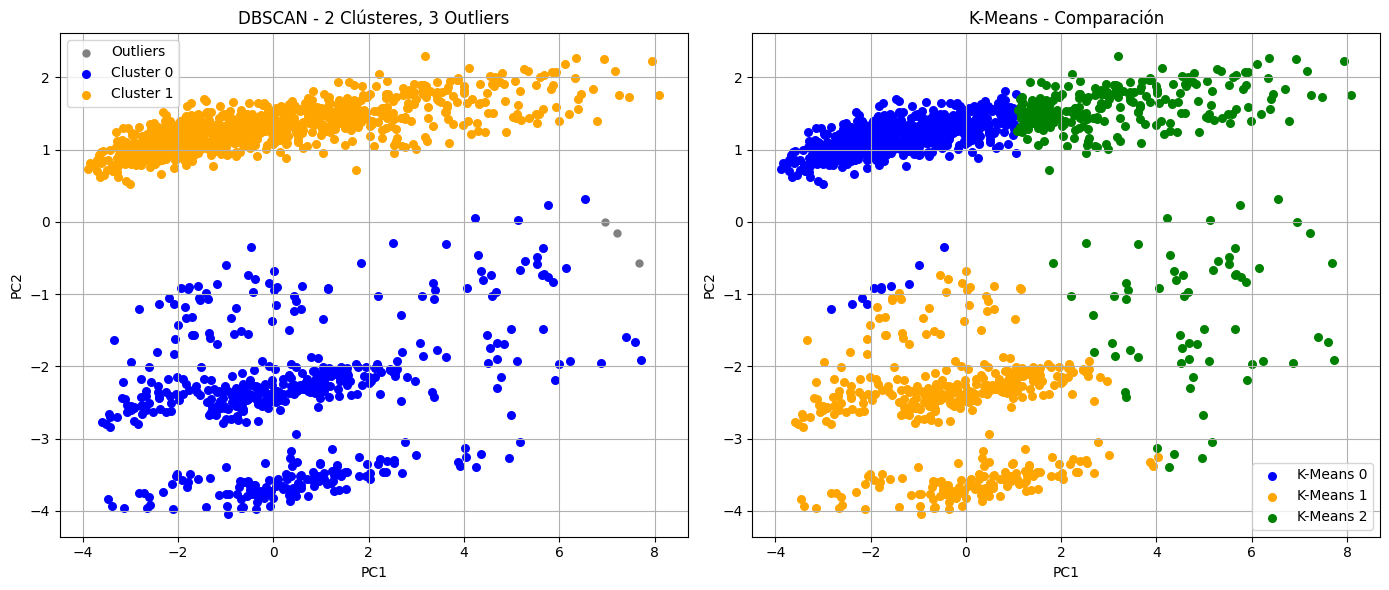


ANÁLISIS DE OUTLIERS

Outliers totales: 3
Outliers que desertaron: 0
Porcentaje de outliers que desertaron: 0.0%
Tasa general de deserción: 16.1%

Outliers tienen tasa similar al promedio

CONCLUSIÓN

K-MEANS:
  • Todos los empleados son asignados a un clúster
  • Más interpretable para RRHH
  • Mejor para: Segmentación general

DBSCAN:
  • Detecta automáticamente outliers
  • No necesita definir número de clústeres
  • Mejor para: Detectar casos especiales

RECOMENDACIÓN:
  • Usar K-Means para segmentación principal
  • Usar DBSCAN para detectar outliers


DBSCAN COMPLETADO


In [42]:
# ============================================================
# DBSCAN - VISUALIZACIÓN Y ANÁLISIS
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("="*60)
print("DBSCAN - VISUALIZACIÓN Y ANÁLISIS")
print("="*60)

# Cargar datos
X_pca_2d = pd.read_csv('X_pca_2d.csv').values
attrition_binary = pd.read_csv('attrition_binary.csv')
df_clusters = pd.read_csv('clusters_dbscan.csv')

# Cargar K-Means si existe
try:
    df_kmeans = pd.read_csv('clusters_kmeans.csv')
    clusters_kmeans = df_kmeans['Cluster'].values
    tiene_kmeans = True
except:
    tiene_kmeans = False
    print("\nNo se encontró clusters_kmeans.csv")

clusters_dbscan = df_clusters['Cluster_DBSCAN'].values

# ============================================================
# CONTAR RESULTADOS
# ============================================================

# Contar clústeres
unicos = []
for c in clusters_dbscan:
    if c not in unicos:
        unicos.append(c)

n_clusters = len(unicos)
if -1 in unicos:
    n_clusters = n_clusters - 1

# Contar outliers
n_outliers = 0
for c in clusters_dbscan:
    if c == -1:
        n_outliers = n_outliers + 1

pct_outliers = (n_outliers / len(clusters_dbscan)) * 100

print(f"\nRESULTADOS DBSCAN:")
print(f"  Clústeres: {n_clusters}")
print(f"  Outliers: {n_outliers} ({pct_outliers:.1f}%)")

# Distribución
print("\nDistribución por clúster:")
for cluster in sorted(set(clusters_dbscan)):
    contar = 0
    for c in clusters_dbscan:
        if c == cluster:
            contar = contar + 1

    if cluster == -1:
        print(f"  Outliers: {contar}")
    else:
        print(f"  Cluster {cluster}: {contar}")

# ============================================================
# GRÁFICOS
# ============================================================

print("\nGenerando gráficos...")

plt.figure(figsize=(14, 6))

# Gráfico 1: DBSCAN
plt.subplot(1, 2, 1)

colores = ['blue', 'orange', 'green', 'red', 'purple', 'brown', 'pink']

for cluster in sorted(set(clusters_dbscan)):
    puntos = []
    for i in range(len(clusters_dbscan)):
        if clusters_dbscan[i] == cluster:
            puntos.append(i)

    if len(puntos) > 0:
        x = [X_pca_2d[i][0] for i in puntos]
        y = [X_pca_2d[i][1] for i in puntos]

        if cluster == -1:
            plt.scatter(x, y, c='gray', label='Outliers', s=25)
        else:
            plt.scatter(x, y, c=colores[cluster % len(colores)], label=f'Cluster {cluster}', s=30)

plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title(f'DBSCAN - {n_clusters} Clústeres, {n_outliers} Outliers')
plt.legend()
plt.grid(True)

# Gráfico 2: Comparación con K-Means
if tiene_kmeans:
    plt.subplot(1, 2, 2)

    for i in range(len(set(clusters_kmeans))):
        puntos = []
        for j in range(len(clusters_kmeans)):
            if clusters_kmeans[j] == i:
                puntos.append(j)

        if len(puntos) > 0:
            x = [X_pca_2d[j][0] for j in puntos]
            y = [X_pca_2d[j][1] for j in puntos]
            plt.scatter(x, y, c=colores[i % len(colores)], label=f'K-Means {i}', s=30)

    plt.xlabel('PC1')
    plt.ylabel('PC2')
    plt.title('K-Means - Comparación')
    plt.legend()
    plt.grid(True)

plt.tight_layout()
plt.show()

# ============================================================
# ANÁLISIS DE OUTLIERS
# ============================================================

print("\n" + "="*60)
print("ANÁLISIS DE OUTLIERS")
print("="*60)

attrition_values = attrition_binary.values.flatten()

if n_outliers > 0:
    # Contar outliers que desertaron
    outliers_desertaron = 0
    for i in range(len(clusters_dbscan)):
        if clusters_dbscan[i] == -1 and attrition_values[i] == 1:
            outliers_desertaron = outliers_desertaron + 1

    # Tasa general de deserción
    total_desertaron = 0
    for val in attrition_values:
        if val == 1:
            total_desertaron = total_desertaron + 1

    pct_outliers_attrition = (outliers_desertaron / n_outliers) * 100
    pct_total_attrition = (total_desertaron / len(attrition_values)) * 100

    print(f"\nOutliers totales: {n_outliers}")
    print(f"Outliers que desertaron: {outliers_desertaron}")
    print(f"Porcentaje de outliers que desertaron: {pct_outliers_attrition:.1f}%")
    print(f"Tasa general de deserción: {pct_total_attrition:.1f}%")

    if pct_outliers_attrition > pct_total_attrition:
        print("\nOUTLIERS TIENEN MAYOR TASA DE DESERCIÓN")
        print("Son empleados 'diferentes' que tienden a irse")
    else:
        print("\nOutliers tienen tasa similar al promedio")
else:
    print("\nNo se detectaron outliers")

# ============================================================
# CONCLUSIÓN
# ============================================================

print("\n" + "="*60)
print("CONCLUSIÓN")
print("="*60)

print("""
K-MEANS:
  • Todos los empleados son asignados a un clúster
  • Más interpretable para RRHH
  • Mejor para: Segmentación general

DBSCAN:
  • Detecta automáticamente outliers
  • No necesita definir número de clústeres
  • Mejor para: Detectar casos especiales

RECOMENDACIÓN:
  • Usar K-Means para segmentación principal
  • Usar DBSCAN para detectar outliers
""")

print("\n" + "="*60)
print("DBSCAN COMPLETADO")
print("="*60)

#5.3.3  Tabla Comparativa de Algoritmos
Presentar una tabla con las métricas de ambos algoritmos:

In [45]:
# RECOPILACIÓN DE MÉTRICAS PARA TABLA COMPARATIVA
from sklearn.metrics import silhouette_score, davies_bouldin_score

print("="*60)
print("RECOPILACIÓN DE MÉTRICAS")
print("="*60)

X_pca_2d = pd.read_csv('X_pca_2d.csv').values

df_kmeans = pd.read_csv('clusters_kmeans.csv')
clusters_kmeans = df_kmeans['Cluster'].values

df_dbscan = pd.read_csv('clusters_dbscan.csv')
clusters_dbscan = df_dbscan['Cluster_DBSCAN'].values

attrition_binary = pd.read_csv('attrition_binary.csv').values.flatten()

print("Datos cargados correctamente")


print("\n" + "-"*40)
print("MÉTRICAS K-MEANS")
print("-"*40)

unicos_kmeans = []
for c in clusters_kmeans:
    if c not in unicos_kmeans:
        unicos_kmeans.append(c)

n_clusters_kmeans = len(unicos_kmeans)

if n_clusters_kmeans > 1:
    silhouette_kmeans = silhouette_score(X_pca_2d, clusters_kmeans)
    davies_kmeans = davies_bouldin_score(X_pca_2d, clusters_kmeans)
else:
    silhouette_kmeans = "N/A"
    davies_kmeans = "N/A"

outliers_kmeans = 0
pct_outliers_kmeans = 0

print(f"  Clústeres: {n_clusters_kmeans}")

if isinstance(silhouette_kmeans, float):
    print(f"  Silhouette Score: {silhouette_kmeans:.4f}")
else:
    print(f"  Silhouette Score: {silhouette_kmeans}")

if isinstance(davies_kmeans, float):
    print(f"  Davies-Bouldin: {davies_kmeans:.4f}")
else:
    print(f"  Davies-Bouldin: {davies_kmeans}")

print(f"  Outliers: {outliers_kmeans} (0%)")

#METRICAS

print("\n" + "-"*40)
print("MÉTRICAS DBSCAN")
print("-"*40)

unicos_dbscan = []
for c in clusters_dbscan:
    if c not in unicos_dbscan:
        unicos_dbscan.append(c)

n_clusters_dbscan = len(unicos_dbscan)
if -1 in unicos_dbscan:
    n_clusters_dbscan = n_clusters_dbscan - 1

n_outliers_dbscan = 0
for c in clusters_dbscan:
    if c == -1:
        n_outliers_dbscan = n_outliers_dbscan + 1

pct_outliers_dbscan = (n_outliers_dbscan / len(clusters_dbscan)) * 100

#métricas
if n_clusters_dbscan > 1:
    # Filtrar outliers
    indices_validos = []
    for i in range(len(clusters_dbscan)):
        if clusters_dbscan[i] != -1:
            indices_validos.append(i)

    if len(indices_validos) > 0:
        X_valid = []
        clusters_valid = []
        for i in indices_validos:
            X_valid.append(X_pca_2d[i])
            clusters_valid.append(clusters_dbscan[i])

        X_valid = np.array(X_valid)
        clusters_valid = np.array(clusters_valid)

        unicos_valid = []
        for c in clusters_valid:
            if c not in unicos_valid:
                unicos_valid.append(c)

        if len(unicos_valid) > 1:
            silhouette_dbscan = silhouette_score(X_valid, clusters_valid)
            davies_dbscan = davies_bouldin_score(X_valid, clusters_valid)
        else:
            silhouette_dbscan = "N/A"
            davies_dbscan = "N/A"
    else:
        silhouette_dbscan = "N/A"
        davies_dbscan = "N/A"
else:
    silhouette_dbscan = "N/A"
    davies_dbscan = "N/A"

print(f"  Clústeres: {n_clusters_dbscan}")

if isinstance(silhouette_dbscan, float):
    print(f"  Silhouette Score: {silhouette_dbscan:.4f}")
else:
    print(f"  Silhouette Score: {silhouette_dbscan}")

if isinstance(davies_dbscan, float):
    print(f"  Davies-Bouldin: {davies_dbscan:.4f}")
else:
    print(f"  Davies-Bouldin: {davies_dbscan}")

print(f"  Outliers: {n_outliers_dbscan} ({pct_outliers_dbscan:.1f}%)")



print("\n" + "-"*40)
print("SELECCIÓN DEL MEJOR MODELO")
print("-"*40)

mejor_modelo = "K-Means"
razon = ""

if isinstance(silhouette_kmeans, float) and isinstance(silhouette_dbscan, float):
    if silhouette_dbscan > silhouette_kmeans:
        mejor_modelo = "DBSCAN"
        razon = f"Silhouette más alto ({silhouette_dbscan:.4f} vs {silhouette_kmeans:.4f})"
    elif silhouette_kmeans > silhouette_dbscan:
        mejor_modelo = "K-Means"
        razon = f"Silhouette más alto ({silhouette_kmeans:.4f} vs {silhouette_dbscan:.4f})"
    else:
        mejor_modelo = "Empate"
        razon = "Silhouette similares"
else:
    mejor_modelo = "K-Means"
    razon = "DBSCAN no tiene Silhouette válido"

print(f"\nMejor modelo: {mejor_modelo}")
print(f"  Razón: {razon}")


metricas_kmeans = []
metricas_dbscan = []

if isinstance(silhouette_kmeans, float):
    metricas_kmeans.append(f"{silhouette_kmeans:.4f}")
else:
    metricas_kmeans.append(silhouette_kmeans)

if isinstance(silhouette_dbscan, float):
    metricas_dbscan.append(f"{silhouette_dbscan:.4f}")
else:
    metricas_dbscan.append(silhouette_dbscan)

if isinstance(davies_kmeans, float):
    metricas_kmeans.append(f"{davies_kmeans:.4f}")
else:
    metricas_kmeans.append(davies_kmeans)

if isinstance(davies_dbscan, float):
    metricas_dbscan.append(f"{davies_dbscan:.4f}")
else:
    metricas_dbscan.append(davies_dbscan)

#clusteres
metricas_kmeans.append(str(n_clusters_kmeans))
metricas_dbscan.append(str(n_clusters_dbscan))

#outliers
metricas_kmeans.append(f"{pct_outliers_kmeans:.1f}%")
metricas_dbscan.append(f"{pct_outliers_dbscan:.1f}%")

#interpretabilidad
metricas_kmeans.append("Alta - Clústeres claros")

if n_clusters_dbscan == 0:
    metricas_dbscan.append("Baja - Sin clústeres")
elif n_outliers_dbscan > len(clusters_dbscan) * 0.3:
    metricas_dbscan.append("Media - Muchos outliers")
else:
    metricas_dbscan.append("Media - Clústeres con outliers")

#crear DataFrame
df_metricas = pd.DataFrame({
    'Métrica': ['Silhouette Score', 'Davies-Bouldin', 'N° Clústeres', '% Outliers', 'Interpretabilidad'],
    'K-Means': metricas_kmeans,
    'DBSCAN': metricas_dbscan,
    'Mejor': [mejor_modelo if i == 0 else '-' for i in range(5)]
})

df_metricas.to_csv('tabla_comparativa.csv', index=False)

print("\nArchivo guardado: tabla_comparativa.csv")

print("\n" + "="*60)
print("MÉTRICAS RECOPILADAS")
print("="*60)

RECOPILACIÓN DE MÉTRICAS
Datos cargados correctamente

----------------------------------------
MÉTRICAS K-MEANS
----------------------------------------
  Clústeres: 3
  Silhouette Score: 0.5506
  Davies-Bouldin: 0.6516
  Outliers: 0 (0%)

----------------------------------------
MÉTRICAS DBSCAN
----------------------------------------
  Clústeres: 2
  Silhouette Score: 0.4618
  Davies-Bouldin: 1.0013
  Outliers: 3 (0.2%)

----------------------------------------
SELECCIÓN DEL MEJOR MODELO
----------------------------------------

Mejor modelo: K-Means
  Razón: Silhouette más alto (0.5506 vs 0.4618)

Archivo guardado: tabla_comparativa.csv

MÉTRICAS RECOPILADAS


TABLA COMPARATIVA DE ALGORITMOS

TABLA COMPARATIVA: K-MEANS vs DBSCAN
Silhouette Score     | 0.5506          | 0.4618          | K-Means   
Davies-Bouldin       | 0.6516          | 1.0013          | -         
N° Clústeres         | 3               | 2               | -         
% Outliers           | 0.0%            | 0.2%            | -         
Interpretabilidad    | Alta - Clústeres claros | Media - Clústeres con outliers | -         

Generando tabla con formato...


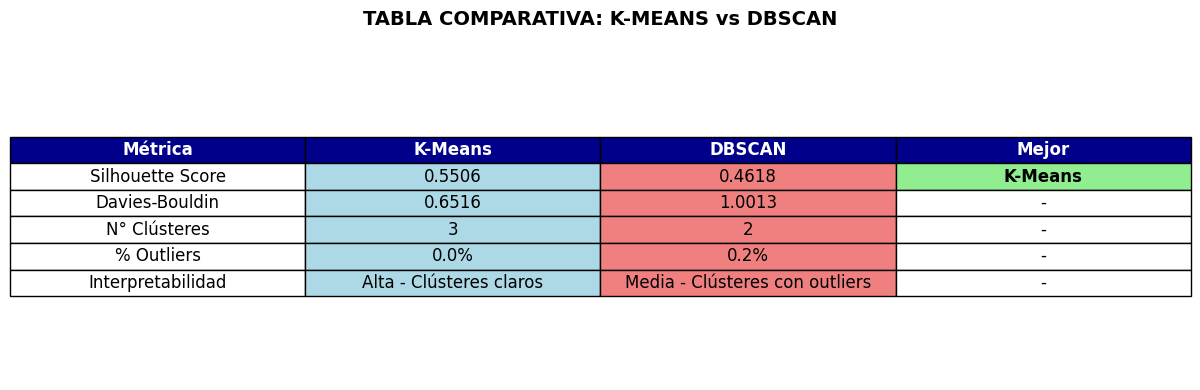


CONCLUSIÓN FINAL

MEJOR MODELO: K-Means

RECOMENDACIÓN:
  • Usar K-Means para segmentación de empleados
  • Los clústeres permitirán identificar perfiles de riesgo


TABLA COMPARATIVA COMPLETADA


In [47]:

# TABLA COMPARATIVA DE ALGORITMOS

import pandas as pd
import matplotlib.pyplot as plt

print("="*60)
print("TABLA COMPARATIVA DE ALGORITMOS")
print("="*60)

df_metricas = pd.read_csv('tabla_comparativa.csv')

print("\n" + "="*70)
print("TABLA COMPARATIVA: K-MEANS vs DBSCAN")
print("="*70)

#fila por fila
for i in range(len(df_metricas)):
    fila = df_metricas.iloc[i]
    print(f"{fila['Métrica']:20} | {fila['K-Means']:15} | {fila['DBSCAN']:15} | {fila['Mejor']:10}")

print("="*70)

# TABLA CON COLORES

print("\nGenerando tabla con formato...")

fig, ax = plt.subplots(figsize=(12, 4))
ax.axis('tight')
ax.axis('off')

datos_tabla = []
for i in range(len(df_metricas)):
    fila = df_metricas.iloc[i]
    datos_tabla.append([
        fila['Métrica'],
        fila['K-Means'],
        fila['DBSCAN'],
        fila['Mejor']
    ])

columnas = ['Métrica', 'K-Means', 'DBSCAN', 'Mejor']

tabla = ax.table(cellText=datos_tabla,
                 colLabels=columnas,
                 cellLoc='center',
                 loc='center')

tabla.auto_set_font_size(False)
tabla.set_fontsize(12)
tabla.scale(1.2, 1.5)

for (i, j), cell in tabla.get_celld().items():
    if i == 0:  # Header
        cell.set_text_props(color='white', fontweight='bold')
        cell.set_facecolor('darkblue')
    elif j == 3:  # Columna "Mejor"
        texto = cell.get_text().get_text()
        if texto != '-':
            cell.set_facecolor('lightgreen')
            cell.set_text_props(fontweight='bold')
    elif j == 1:  # Columna K-Means
        cell.set_facecolor('lightblue')
    elif j == 2:  # Columna DBSCAN
        cell.set_facecolor('lightcoral')

plt.title('TABLA COMPARATIVA: K-MEANS vs DBSCAN', fontsize=14, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()

#FINAL

print("\n" + "="*60)
print("CONCLUSIÓN FINAL")
print("="*60)

mejor_modelo = ""
for i in range(len(df_metricas)):
    if df_metricas.iloc[i]['Mejor'] != '-':
        mejor_modelo = df_metricas.iloc[i]['Mejor']
        break

if mejor_modelo == "":
    mejor_modelo = "K-Means"

print(f"""
MEJOR MODELO: {mejor_modelo}

RECOMENDACIÓN:
  • Usar {mejor_modelo} para segmentación de empleados
  • Los clústeres permitirán identificar perfiles de riesgo
""")

print("\n" + "="*60)
print("TABLA COMPARATIVA COMPLETADA")
print("="*60)

# 5.4  Etapa 4 — Análisis de Deserción por Clúster Esta es la etapa más crítica del proyecto. Una vez obtenidos los clústeres del mejor modelo:
17. Calcular la tasa de Attrition (%) para cada clúster.
18. Calcular el perfil promedio de cada clúster (media de variables numéricas + moda de variables categóricas).
19. Crear un heatmap de perfiles: filas = clústeres, columnas = variables clave, valores = Z-score normalizado.
20. Identificar el/los clúster(s) de alto riesgo (tasa de deserción >30%) y el/los de bajo riesgo (<10%).
21. Asignar nombres descriptivos a cada clúster basados en sus características dominantes.

Calcular la tasa de Attrition (%) para cada clúster.

In [48]:
# ANÁLISIS DE DESERCIÓN POR CLÚSTER

print("="*60)
print("ANÁLISIS DE DESERCIÓN POR CLÚSTER")
print("="*60)

df_clusters = pd.read_csv('clusters_kmeans.csv')
attrition_binary = pd.read_csv('attrition_binary.csv')
df_clean = pd.read_csv('empleados-ACMELabs.csv')

df_clusters['Attrition'] = attrition_binary.values
df_clusters['Attrition_Original'] = df_clean['Attrition'].values

#TASA POR CLÚSTER

print("\n" + "-"*40)
print("TASA DE DESERCIÓN POR CLÚSTER")
print("-"*40)

#clusteres únicos
clusters_unicos = []
for c in df_clusters['Cluster']:
    if c not in clusters_unicos:
        clusters_unicos.append(c)

#métricas por clúster
resultados = []

for cluster in clusters_unicos:
    #Filtrar_datos del clúster
    datos_cluster = []
    for i in range(len(df_clusters)):
        if df_clusters.iloc[i]['Cluster'] == cluster:
            datos_cluster.append(i)

    total = len(datos_cluster)

    #desertores
    desertores = 0
    for i in datos_cluster:
        if df_clusters.iloc[i]['Attrition'] == 1:
            desertores = desertores + 1

    tasa = desertores / total

    resultados.append({
        'Cluster': cluster,
        'Total': total,
        'Desertores': desertores,
        'Tasa': tasa,
        'Tasa_Porcentaje': tasa * 100
    })

#mayor a menor
for i in range(len(resultados)):
    for j in range(i + 1, len(resultados)):
        if resultados[i]['Tasa'] < resultados[j]['Tasa']:
            temp = resultados[i]
            resultados[i] = resultados[j]
            resultados[j] = temp

print("\nCluster | Total | Desertores | Tasa %")
print("-"*45)

for r in resultados:
    print(f"  {r['Cluster']:2d}    |  {r['Total']:3d}   |    {r['Desertores']:3d}    |  {r['Tasa_Porcentaje']:5.1f}%")

#CLÚSTERES DE ALTO Y BAJO RIESGO

print("\n" + "-"*40)
print("IDENTIFICACIÓN DE CLÚSTERES DE RIESGO")
print("-"*40)

for r in resultados:
    tasa = r['Tasa_Porcentaje']

    if tasa > 30:
        nivel = "ALTO RIESGO"
    elif tasa < 10:
        nivel = "BAJO RIESGO"
    else:
        nivel = "RIESGO MODERADO"

    print(f"\nCluster {r['Cluster']}: {tasa:.1f}% deserción - {nivel}")

# GUARDAR RESULTADOS

#DataFrame
df_tasa = pd.DataFrame({
    'Cluster': [r['Cluster'] for r in resultados],
    'Total_Empleados': [r['Total'] for r in resultados],
    'N_Desertores': [r['Desertores'] for r in resultados],
    'Tasa_Desercion': [r['Tasa'] for r in resultados],
    'Tasa_Porcentaje': [r['Tasa_Porcentaje'] for r in resultados]
})

df_tasa.to_csv('tasa_attrition_por_cluster.csv', index=False)

print("\nArchivo guardado: tasa_attrition_por_cluster.csv")
print("\n" + "="*60)
print("ANÁLISIS COMPLETADO")
print("="*60)

ANÁLISIS DE DESERCIÓN POR CLÚSTER

----------------------------------------
TASA DE DESERCIÓN POR CLÚSTER
----------------------------------------

Cluster | Total | Desertores | Tasa %
---------------------------------------------
   1    |  434   |     98    |   22.6%
   0    |  732   |    121    |   16.5%
   2    |  304   |     18    |    5.9%

----------------------------------------
IDENTIFICACIÓN DE CLÚSTERES DE RIESGO
----------------------------------------

Cluster 1: 22.6% deserción - RIESGO MODERADO

Cluster 0: 16.5% deserción - RIESGO MODERADO

Cluster 2: 5.9% deserción - BAJO RIESGO

Archivo guardado: tasa_attrition_por_cluster.csv

ANÁLISIS COMPLETADO


. Calcular el perfil promedio de cada clúster (media de variables numéricas + moda de variables categóricas).

In [49]:
#PERFIL PROMEDIO DE CADA CLÚSTER

print("="*60)
print("PERFIL PROMEDIO DE CADA CLÚSTER")
print("="*60)

df_clusters = pd.read_csv('clusters_kmeans.csv')
df_clean = pd.read_csv('empleados-ACMELabs.csv')

df_completo = df_clean.copy()
df_completo['Cluster'] = df_clusters['Cluster'].values

#VARIABLES NUMÉRICAS - CALCULAR MEDIA POR CLÚSTER

print("\n" + "-"*40)
print("VARIABLES NUMÉRICAS (MEDIA POR CLÚSTER)")
print("-"*40)

#variables numéricas
vars_numericas = ['Age', 'MonthlyIncome', 'YearsAtCompany',
                  'TotalWorkingYears', 'JobSatisfaction',
                  'EnvironmentSatisfaction', 'WorkLifeBalance',
                  'DistanceFromHome', 'TrainingTimesLastYear']

# cl únicos
clusters_unicos = []
for c in df_completo['Cluster']:
    if c not in clusters_unicos:
        clusters_unicos.append(c)

#media por cl
resultados_numericos = {}

for var in vars_numericas:
    resultados_numericos[var] = []
    for cluster in clusters_unicos:
        # Filtrar de cl
        valores = []
        for i in range(len(df_completo)):
            if df_completo.iloc[i]['Cluster'] == cluster:
                valores.append(df_completo.iloc[i][var])

        #media
        if len(valores) > 0:
            media = sum(valores) / len(valores)
        else:
            media = 0

        resultados_numericos[var].append(round(media, 2))

#tabla numérica
print("\nCluster |", end="")
for var in vars_numericas:
    print(f" {var:20} |", end="")
print()

print("-" * (10 + 22 * len(vars_numericas)))

for idx, cluster in enumerate(clusters_unicos):
    print(f"  {cluster:2d}    |", end="")
    for var in vars_numericas:
        print(f" {resultados_numericos[var][idx]:20.2f} |", end="")
    print()

# VARIABLES CATEGÓRICAS - CALCULAR MODA POR CLÚSTER

print("\n" + "-"*40)
print("VARIABLES CATEGÓRICAS (MODA POR CLÚSTER)")
print("-"*40)

vars_categoricas = ['Department', 'JobRole', 'MaritalStatus', 'OverTime', 'Gender']

resultados_categoricos = {}

for var in vars_categoricas:
    resultados_categoricos[var] = []
    for cluster in clusters_unicos:
        #datos del clúster
        valores = []
        for i in range(len(df_completo)):
            if df_completo.iloc[i]['Cluster'] == cluster:
                valores.append(df_completo.iloc[i][var])

        #moda
        if len(valores) > 0:
            #frecuencia
            frecuencia = {}
            for v in valores:
                if v not in frecuencia:
                    frecuencia[v] = 0
                frecuencia[v] = frecuencia[v] + 1

            #frecuente
            moda = None
            max_freq = 0
            for v, f in frecuencia.items():
                if f > max_freq:
                    max_freq = f
                    moda = v
        else:
            moda = 'N/A'

        resultados_categoricos[var].append(moda)

#tabla categórica
print("\nCluster |", end="")
for var in vars_categoricas:
    print(f" {var:20} |", end="")
print()

print("-" * (10 + 22 * len(vars_categoricas)))

for idx, cluster in enumerate(clusters_unicos):
    print(f"  {cluster:2d}    |", end="")
    for var in vars_categoricas:
        print(f" {resultados_categoricos[var][idx]:20} |", end="")
    print()

# PERFIL COMPLETO POR CLÚSTER

print("\n" + "-"*40)
print("PERFIL COMPLETO - CLÚSTER POR CLÚSTER")
print("-"*40)

#tasa de deserción
df_tasa = pd.read_csv('tasa_attrition_por_cluster.csv')

# diccionario de tasas
tasa_dict = {}
for i in range(len(df_tasa)):
    cluster = df_tasa.iloc[i]['Cluster']
    tasa = df_tasa.iloc[i]['Tasa_Porcentaje']
    tasa_dict[cluster] = tasa

#perfil completo
print("\nRESUMEN POR CLÚSTER:")
print("="*70)

for cluster in clusters_unicos:
    print(f"\nCLUSTER {cluster}:")
    print("-"*40)

    #deserción
    tasa = tasa_dict.get(cluster, 0)
    print(f"  Tasa de Deserción: {tasa:.1f}%")

    # Variables nm
    print("  Perfil Numérico:")
    for var in vars_numericas[:5]:
        idx = clusters_unicos.index(cluster)
        valor = resultados_numericos[var][idx]
        print(f"    • {var}: {valor:.2f}")

    #variables ct
    print("  Perfil Categórico:")
    for var in vars_categoricas:
        idx = clusters_unicos.index(cluster)
        valor = resultados_categoricos[var][idx]
        print(f"    • {var}: {valor}")


# GUARDAR RESULTADOS

# Crear DataFrame con perfil completo
datos_guardar = {'Cluster': clusters_unicos}

datos_guardar['Tasa_Desercion_%'] = [tasa_dict.get(c, 0) for c in clusters_unicos]

#variables nm
for var in vars_numericas:
    datos_guardar[var] = resultados_numericos[var]

#variables ct
for var in vars_categoricas:
    datos_guardar[var] = resultados_categoricos[var]

df_perfil = pd.DataFrame(datos_guardar)
df_perfil.to_csv('perfil_clusters.csv', index=False)

print("\nArchivo guardado: perfil_clusters.csv")
print("\n" + "="*60)
print("PERFIL DE CLÚSTERES COMPLETADO")
print("="*60)

PERFIL PROMEDIO DE CADA CLÚSTER

----------------------------------------
VARIABLES NUMÉRICAS (MEDIA POR CLÚSTER)
----------------------------------------

Cluster | Age                  | MonthlyIncome        | YearsAtCompany       | TotalWorkingYears    | JobSatisfaction      | EnvironmentSatisfaction | WorkLifeBalance      | DistanceFromHome     | TrainingTimesLastYear |
----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
   1    |                35.06 |              5757.40 |                 5.84 |                 9.12 |                 2.76 |                 2.67 |                 2.82 |                 9.48 |                 2.85 |
   0    |                34.70 |              4071.33 |                 4.76 |                 8.02 |                 2.74 |                 2.74 |                 2.72 |                 9.09 |    

 Crear un heatmap de perfiles: filas = clústeres, columnas = variables clave, valores = Z-score normalizado.

HEATMAP DE PERFILES POR CLÚSTER

Z-Score de cada clúster por variable:
          Age  MonthlyIncome  YearsAtCompany  TotalWorkingYears  JobSatisfaction  EnvironmentSatisfaction  WorkLifeBalance
Cluster                                                                                                                   
1       -0.67          -0.49           -0.57              -0.62             0.91                    -1.40             1.22
0       -0.74          -0.90           -0.83              -0.79             0.49                     0.56            -1.22
2        1.41           1.39            1.41               1.41            -1.39                     0.84             0.00

Generando heatmap...


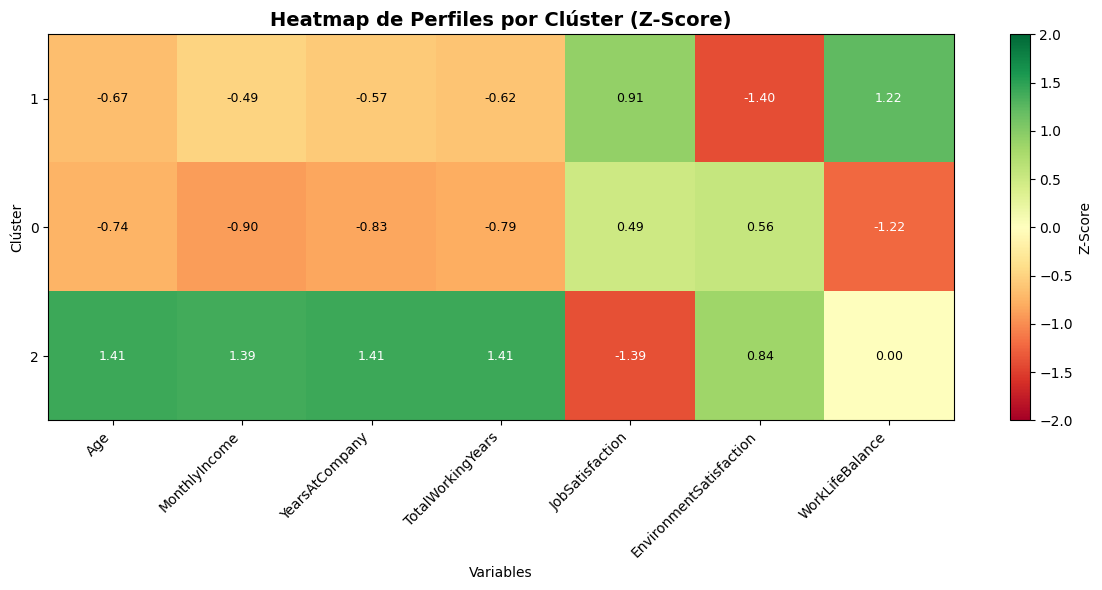


Archivo guardado: perfil_zscore_clusters.csv

HEATMAP COMPLETADO


In [50]:
# HEATMAP DE PERFILES POR CLÚSTER


print("="*60)
print("HEATMAP DE PERFILES POR CLÚSTER")
print("="*60)

perfil = pd.read_csv('perfil_clusters.csv', index_col=0)

#variables nm
vars_heatmap = ['Age', 'MonthlyIncome', 'YearsAtCompany',
                'TotalWorkingYears', 'JobSatisfaction',
                'EnvironmentSatisfaction', 'WorkLifeBalance']

#matriz
perfil_numerico = []
for var in vars_heatmap:
    columna = []
    for idx in perfil.index:
        columna.append(perfil.loc[idx, var])
    perfil_numerico.append(columna)

#DataFrame
perfil_numerico = pd.DataFrame(
    np.array(perfil_numerico).T,
    columns=vars_heatmap,
    index=perfil.index
)

#Z-score
perfil_zscore = perfil_numerico.copy()

for var in perfil_zscore.columns:
    #media y desviación
    valores = perfil_zscore[var].values
    media = sum(valores) / len(valores)

    #desviación estándar
    diferencias = []
    for v in valores:
        diferencias.append((v - media) ** 2)
    std = (sum(diferencias) / len(valores)) ** 0.5

    #Z-score
    if std != 0:
        for i in range(len(valores)):
            perfil_zscore.loc[perfil_zscore.index[i], var] = (valores[i] - media) / std
    else:
        for i in range(len(valores)):
            perfil_zscore.loc[perfil_zscore.index[i], var] = 0

perfil_zscore = perfil_zscore.round(2)

print("\nZ-Score de cada clúster por variable:")
print(perfil_zscore.to_string())

#HEATMAP

print("\nGenerando heatmap...")

#figura
plt.figure(figsize=(12, 6))

#datos d heatmap
datos = perfil_zscore.values
filas = perfil_zscore.index.tolist()
columnas = perfil_zscore.columns.tolist()

#heatmap con imshow
plt.imshow(datos, cmap='RdYlGn', aspect='auto', vmin=-2, vmax=2)


plt.colorbar(label='Z-Score')

#etiquetas
plt.xticks(range(len(columnas)), columnas, rotation=45, ha='right')
plt.yticks(range(len(filas)), filas)

#valores
for i in range(len(filas)):
    for j in range(len(columnas)):
        valor = datos[i, j]
        color = 'white' if abs(valor) > 1 else 'black'
        plt.text(j, i, f'{valor:.2f}', ha='center', va='center', color=color, fontsize=9)

plt.title('Heatmap de Perfiles por Clúster (Z-Score)', fontsize=14, fontweight='bold')
plt.xlabel('Variables')
plt.ylabel('Clúster')

plt.tight_layout()
plt.show()

# GUARDAR RESULTADOS

perfil_zscore.to_csv('perfil_zscore_clusters.csv')

print("\nArchivo guardado: perfil_zscore_clusters.csv")
print("\n" + "="*60)
print("HEATMAP COMPLETADO")
print("="*60)

20. Identificar el/los clúster(s) de alto riesgo (tasa de deserción >30%) y el/los de bajo riesgo (<10%).

In [51]:
# ASIGNACIÓN DE NOMBRES A CLÚSTERES

print("="*60)
print("ASIGNACIÓN DE NOMBRES A CLÚSTERES")
print("="*60)

perfil = pd.read_csv('perfil_clusters.csv', index_col=0)
tasa_attrition = pd.read_csv('tasa_attrition_por_cluster.csv', index_col=0)

#ANALIZAR CADA CLÚSTER PARA ASIGNAR NOMBRE

print("\n" + "-"*40)
print("ANÁLISIS DE CADA CLÚSTER")
print("-"*40)

nombres_clusters = {}

for cluster in perfil.index:
    #datos del clúster
    tasa = tasa_attrition.loc[cluster, 'Tasa_Porcentaje']
    edad = perfil.loc[cluster, 'Age']
    salario = perfil.loc[cluster, 'MonthlyIncome']
    antiguedad = perfil.loc[cluster, 'YearsAtCompany']
    satisfaccion = perfil.loc[cluster, 'JobSatisfaction']
    overtime = perfil.loc[cluster, 'OverTime']

    #columnas
    if 'Department' in perfil.columns:
        department = perfil.loc[cluster, 'Department']
    else:
        department = 'N/A'

    if 'JobRole' in perfil.columns:
        jobrole = perfil.loc[cluster, 'JobRole']
    else:
        jobrole = 'N/A'

    #inf
    print(f"\nCLUSTER {cluster}:")
    print(f"  Tasa deserción: {tasa:.1f}%")
    print(f"  Edad: {edad:.0f} años")
    print(f"  Salario: ${salario:,.0f}")
    print(f"  Antigüedad: {antiguedad:.1f} años")
    print(f"  Satisfacción: {satisfaccion:.1f}/4")
    print(f"  OverTime: {overtime}")
    print(f"  Departamento: {department}")
    print(f"  Rol: {jobrole}")

    if tasa > 30:
        if antiguedad < 3 and salario < 5000 and overtime == 'Yes':
            nombre = "Jóvenes con Sobrecarga"
        elif salario < 4000 and satisfaccion < 2.5:
            nombre = "Insatisfechos y Mal Pagados"
        elif antiguedad < 2 and satisfaccion < 2.5:
            nombre = "Nuevos Insatisfechos"
        else:
            nombre = "Alto Riesgo"

    elif tasa < 10:
        if antiguedad > 10 and salario > 10000:
            nombre = "Ejecutivos Estables"
        elif satisfaccion > 3.5 and salario > 7000:
            nombre = "Profesionales Satisfechos"
        elif antiguedad > 5 and salario > 5000:
            nombre = "Empleados Leales"
        else:
            nombre = "Bajo Riesgo"

    else:
        if overtime == 'Yes' and satisfaccion < 3:
            nombre = "Sobrecargados"
        elif satisfaccion > 3.5:
            nombre = "Satisfechos"
        elif salario < 5000 and antiguedad < 5:
            nombre = "En Crecimiento"
        elif department == 'Sales':
            nombre = "Vendedores Estables"
        else:
            nombre = f"Cluster {cluster}"

    nombres_clusters[cluster] = nombre

#TABLA DE CLÚSTERES CON NOMBRES

print("\n" + "-"*40)
print("NOMBRES ASIGNADOS A CADA CLÚSTER")
print("-"*40)

#tabla final
print("\nCluster | % Deserción | Desertores | Total | Nombre")
print("-"*70)

for cluster in perfil.index:
    tasa = tasa_attrition.loc[cluster, 'Tasa_Porcentaje']
    desertores = tasa_attrition.loc[cluster, 'N_Desertores']
    total = tasa_attrition.loc[cluster, 'Total_Empleados']
    nombre = nombres_clusters[cluster]

    print(f"  {cluster:2d}    |    {tasa:5.1f}%   |     {desertores:3d}    |  {total:3d}   |  {nombre}")

#GUARDAR RESULTADOS

#DataFrame final
datos_final = {
    'Cluster': [],
    '% Deserción': [],
    'N Desertores': [],
    'Total Empleados': [],
    'Nombre del Clúster': []
}

for cluster in perfil.index:
    datos_final['Cluster'].append(cluster)
    datos_final['% Deserción'].append(tasa_attrition.loc[cluster, 'Tasa_Porcentaje'])
    datos_final['N Desertores'].append(tasa_attrition.loc[cluster, 'N_Desertores'])
    datos_final['Total Empleados'].append(tasa_attrition.loc[cluster, 'Total_Empleados'])
    datos_final['Nombre del Clúster'].append(nombres_clusters[cluster])

df_final = pd.DataFrame(datos_final)
df_final.set_index('Cluster', inplace=True)
df_final.to_csv('nombres_clusters_final.csv')

print("\nArchivo guardado: nombres_clusters_final.csv")

#RESUMEN FINAL

print("\n" + "="*60)
print("RESUMEN FINAL DE CLÚSTERES")
print("="*60)

for cluster in perfil.index:
    nombre = nombres_clusters[cluster]
    tasa = tasa_attrition.loc[cluster, 'Tasa_Porcentaje']

    print(f"\n{nombre}")
    print(f"  Cluster {cluster}")
    print(f"  Tasa de deserción: {tasa:.1f}%")

    if tasa > 30:
        print("  ALTO RIESGO - ¡ACCIONAR!")
    elif tasa < 10:
        print("  BAJO RIESGO - Mantener")
    else:
        print("  RIESGO MODERADO - Monitorear")

print("\n" + "="*60)
print("ETAPA COMPLETADA")
print("="*60)

ASIGNACIÓN DE NOMBRES A CLÚSTERES

----------------------------------------
ANÁLISIS DE CADA CLÚSTER
----------------------------------------

CLUSTER 1:
  Tasa deserción: 22.6%
  Edad: 35 años
  Salario: $5,757
  Antigüedad: 5.8 años
  Satisfacción: 2.8/4
  OverTime: No
  Departamento: Sales
  Rol: Sales Executive

CLUSTER 0:
  Tasa deserción: 16.5%
  Edad: 35 años
  Salario: $4,071
  Antigüedad: 4.8 años
  Satisfacción: 2.7/4
  OverTime: No
  Departamento: Research & Development
  Rol: Research Scientist

CLUSTER 2:
  Tasa deserción: 5.9%
  Edad: 45 años
  Salario: $13,422
  Antigüedad: 14.1 años
  Satisfacción: 2.6/4
  OverTime: No
  Departamento: Research & Development
  Rol: Manager

----------------------------------------
NOMBRES ASIGNADOS A CADA CLÚSTER
----------------------------------------

Cluster | % Deserción | Desertores | Total | Nombre
----------------------------------------------------------------------
   1    |     22.6%   |      98    |  434   |  Vendedores Estab